# Carbonatite Geochemical Analysis: PCA, K-Means and CNN

**How to run:** upload the CSV in Step 1, then use **Runtime > Run all** (or run cells from top to bottom). Do not skip cells: later steps need variables created earlier (for example `cluster_labels` from Step 72 and `cluster_log` from Step 91). If the session restarts, run everything again from the top.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, adjusted_rand_score

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving VerplanckMPdatafile.csv to VerplanckMPdatafile.csv


## 1. Data Loading & Overview

In [ ]:
df = pd.read_csv("VerplanckMPdatafile.csv")

df.head()

,Lab_number,Field_ID,Description,Latitude,Longitude,Sample_source,Elevation,Al_pct_ICPAES_MS,Ca_pct_ICPAES_MS,Fe_pct_ICPAES_MS,...,MnO_pct_WDXRF,Na2O_pct_WDXRF,P2O5_pct_WDXRF,SiO2_pct_WDXRF,TiO2_pct_WDXRF,SrO_pct_WDXRF,V2O5_pct_WDXRF,LOI_pct_WDXRF,CO2_pct_IR,C_carbonate_pct_IR
0,C-470507,18MP01,"Carbonatite, upper side of pit",35.4767,-115.5317,outcrop,4680,0.06,25.3,0.29,...,0.22,0.15,0.61,1.55,-0.01,1.03,-0.01,28.0,-9999.0,-9999.0
1,C-470508,18MP03,Blue ore carbonatite,35.4779,-115.5294,outcrop,4677,0.05,17.6,0.94,...,0.36,0.33,0.06,4.41,-0.01,10.70,-0.01,21.9,-9999.0,-9999.0
2,C-470509,18MP04,Black ore carbonatite,35.4793,-115.5331,outcrop,4351,0.04,13.2,0.58,...,-0.01,0.09,0.25,4.17,-0.01,5.25,-0.01,20.0,-9999.0,-9999.0
3,C-470510,18MP05,White ore carbonatite,35.4795,-115.5327,outcrop,4351,0.05,20.7,1.25,...,0.37,0.08,0.52,0.58,-0.01,1.55,-0.01,30.0,-9999.0,-9999.0
4,C-470511,18MP06,Black ore carbonatite,35.4795,-115.5327,outcrop,4351,0.06,11.9,2.60,...,0.86,0.13,0.55,21.40,-0.01,1.04,-0.01,17.9,-9999.0,-9999.0


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 29
Number of columns: 85


In [ ]:
print(df.columns.tolist())

['Lab_number', 'Field_ID', 'Description', 'Latitude', 'Longitude', 'Sample_source', 'Elevation', 'Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'Ti_pct_ICPAES_MS', 'Ag_ppm_ICPAES_MS', 'As_ppm_ICPAES_MS', 'B_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Be_ppm_ICPAES_MS', 'Bi_ppm_ICPAES_MS', 'Cd_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cr_ppm_ICPAES_MS', 'Cs_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Hf_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'In_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Li_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Ni_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Rb_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sc_ppm_ICPAES_MS', 'Se_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sn_ppm

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 85 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Lab_number          29 non-null     object 
 1   Field_ID            29 non-null     object 
 2   Description         29 non-null     object 
 3   Latitude            29 non-null     float64
 4   Longitude           29 non-null     float64
 5   Sample_source       29 non-null     object 
 6   Elevation           29 non-null     int64  
 7   Al_pct_ICPAES_MS    29 non-null     float64
 8   Ca_pct_ICPAES_MS    29 non-null     float64
 9   Fe_pct_ICPAES_MS    29 non-null     float64
 10  K_pct_ICPAES_MS     29 non-null     float64
 11  Mg_pct_ICPAES_MS    29 non-null     float64
 12  P_pct_ICPAES_MS     29 non-null     float64
 13  S_pct_ICPAES_MS     29 non-null     float64
 14  Si_pct_ICPAES_MS    29 non-null     float64
 15  Ti_pct_ICPAES_MS    29 non-null     float64
 16  Ag_ppm_ICP

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Missing values in each column:
Lab_number          0
Field_ID            0
Description         0
Latitude            0
Longitude           0
Sample_source       0
Elevation           0
Al_pct_ICPAES_MS    0
Ca_pct_ICPAES_MS    0
Fe_pct_ICPAES_MS    0
K_pct_ICPAES_MS     0
Mg_pct_ICPAES_MS    0
P_pct_ICPAES_MS     0
S_pct_ICPAES_MS     0
Si_pct_ICPAES_MS    0
Ti_pct_ICPAES_MS    0
Ag_ppm_ICPAES_MS    0
As_ppm_ICPAES_MS    0
B_ppm_ICPAES_MS     0
Ba_ppm_ICPAES_MS    0
dtype: int64


In [ ]:
print("\nNumber of -9999 values:")
print((df == -9999).sum().sum())


Number of -9999 values:
213


In [ ]:
missing_9999 = (df == -9999).sum()

print(missing_9999[missing_9999 > 0].sort_values(ascending=False))

CO2_pct_IR            20
C_carbonate_pct_IR    20
Th_ppm_ICPAES_MS      14
BaO_pct_WDXRF          9
Al2O3_pct_WDXRF        9
Zr_ppm_ICPAES_MS       9
Na2O_pct_WDXRF         9
MnO_pct_WDXRF          9
P2O5_pct_WDXRF         9
CaO_pct_WDXRF          9
K2O_pct_WDXRF          9
MgO_pct_WDXRF          9
Cr2O3_pct_WDXRF        9
Fe2O3_pct_WDXRF        9
SrO_pct_WDXRF          9
TiO2_pct_WDXRF         9
LOI_pct_WDXRF          9
SiO2_pct_WDXRF         9
V2O5_pct_WDXRF         9
Elevation              5
Latitude               5
Longitude              5
dtype: int64


## 2. Data Cleaning

In [ ]:
df_clean = df.copy()

df_clean = df_clean.replace(-9999, np.nan)

print("Total missing values after replacement:",
      df_clean.isnull().sum().sum())

Total missing values after replacement: 213


In [ ]:
missing_values = df_clean.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(missing_values)

CO2_pct_IR            20
C_carbonate_pct_IR    20
Th_ppm_ICPAES_MS      14
BaO_pct_WDXRF          9
Al2O3_pct_WDXRF        9
Zr_ppm_ICPAES_MS       9
Na2O_pct_WDXRF         9
MnO_pct_WDXRF          9
P2O5_pct_WDXRF         9
CaO_pct_WDXRF          9
K2O_pct_WDXRF          9
MgO_pct_WDXRF          9
Cr2O3_pct_WDXRF        9
Fe2O3_pct_WDXRF        9
SrO_pct_WDXRF          9
TiO2_pct_WDXRF         9
LOI_pct_WDXRF          9
SiO2_pct_WDXRF         9
V2O5_pct_WDXRF         9
Elevation              5
Latitude               5
Longitude              5
dtype: int64


In [ ]:
missing_summary = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Percentage': (df_clean.isnull().sum() / len(df_clean)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(
    'Missing_Count',
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
CO2_pct_IR,20,68.965517
C_carbonate_pct_IR,20,68.965517
Th_ppm_ICPAES_MS,14,48.275862
BaO_pct_WDXRF,9,31.034483
Al2O3_pct_WDXRF,9,31.034483
Zr_ppm_ICPAES_MS,9,31.034483
Na2O_pct_WDXRF,9,31.034483
MnO_pct_WDXRF,9,31.034483
P2O5_pct_WDXRF,9,31.034483
CaO_pct_WDXRF,9,31.034483


In [ ]:
print(df[['Lab_number', 'Field_ID', 'Description', 'Sample_source']].to_string(index=False))

Lab_number Field_ID                           Description Sample_source
  C-470507   18MP01        Carbonatite, upper side of pit       outcrop
  C-470508   18MP03                  Blue ore carbonatite       outcrop
  C-470509   18MP04                 Black ore carbonatite       outcrop
  C-470510   18MP05                 White ore carbonatite       outcrop
  C-470511   18MP06                 Black ore carbonatite       outcrop
  C-470512   18MP07                   Friable carbonatite       outcrop
  C-470513  18MP08A                 White ore carbonatite       outcrop
  C-470514  18MP08B                 White ore carbonatite       outcrop
  C-470515   18MP09                 Black ore carbonatite       outcrop
  C-470516   18MP11                 Pink ore carbonatite        outcrop
  C-470517   18MP12       Birthday claim vein carbonatite       outcrop
  C-470518   18MP14                  Pink ore carbonatite       outcrop
  C-470519   18MP15                 Brown ore carbonatite       

In [ ]:
print(df_clean['Description'].value_counts())

Description
White ore carbonatite                    7
Carbonatite composite                    5
Black ore carbonatite                    4
Birthday claim vein carbonatite          2
Blue ore carbonatite                     1
Friable carbonatite                      1
Carbonatite, upper side of pit           1
Pink ore carbonatite                     1
Pink ore carbonatite                     1
black and brown ore carbonatite          1
Brown ore carbonatite                    1
Calcite carbonatite                      1
Barite-calcite-bastnasite carbonatite    1
black ore carbonatite                    1
Carbonatite                              1
Name: count, dtype: int64


In [ ]:
df_clean['Description'] = (
    df_clean['Description']
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df_clean['Description'].value_counts())

Description
white ore carbonatite                    7
black ore carbonatite                    5
carbonatite composite                    5
pink ore carbonatite                     2
birthday claim vein carbonatite          2
friable carbonatite                      1
blue ore carbonatite                     1
carbonatite, upper side of pit           1
brown ore carbonatite                    1
black and brown ore carbonatite          1
calcite carbonatite                      1
barite-calcite-bastnasite carbonatite    1
carbonatite                              1
Name: count, dtype: int64


In [ ]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,24.0,35.479363,3.120175e-03,35.4767,35.478175,35.4785,35.47935,35.4892
Longitude,24.0,-115.532458,1.429477e-03,-115.5363,-115.532725,-115.5325,-115.53170,-115.5294
Elevation,24.0,4461.875000,1.880102e+02,4345.0000,4350.750000,4385.5000,4422.00000,4989.0000
Al_pct_ICPAES_MS,29.0,0.077586,5.736196e-02,0.0300,0.040000,0.0500,0.10000,0.2500
Ca_pct_ICPAES_MS,29.0,14.177586,5.394678e+00,0.1700,12.200000,13.8000,16.80000,25.3000
...,...,...,...,...,...,...,...,...
SrO_pct_WDXRF,20.0,3.561000,3.989040e+00,0.2700,0.700000,1.6100,5.89000,13.1000
V2O5_pct_WDXRF,20.0,-0.010000,1.779789e-18,-0.0100,-0.010000,-0.0100,-0.01000,-0.0100
LOI_pct_WDXRF,20.0,22.952500,5.075521e+00,8.8500,20.850000,23.0000,26.82500,30.0000
CO2_pct_IR,9.0,24.552222,8.549973e+00,5.9700,23.100000,27.2000,28.90000,33.2000


In [ ]:
negative_values = (df_clean.select_dtypes(include=np.number) < 0).sum()

print(negative_values[negative_values > 0].sort_values(ascending=False))

Tl_ppm_ICPAES_MS    29
Te_ppm_ICPAES_MS    29
In_ppm_ICPAES_MS    29
Ti_pct_ICPAES_MS    28
Ta_ppm_ICPAES_MS    28
Hf_ppm_ICPAES_MS    28
B_ppm_ICPAES_MS     26
Longitude           24
Ag_ppm_ICPAES_MS    24
Cs_ppm_ICPAES_MS    23
Cr_ppm_ICPAES_MS    23
Se_ppm_ICPAES_MS    22
Sn_ppm_ICPAES_MS    22
V2O5_pct_WDXRF      20
Be_ppm_ICPAES_MS    20
Cr2O3_pct_WDXRF     20
TiO2_pct_WDXRF      19
Li_ppm_ICPAES_MS    17
Ni_ppm_ICPAES_MS    17
Bi_ppm_ICPAES_MS    17
Sc_ppm_ICPAES_MS    15
K2O_pct_WDXRF       12
Cd_ppm_ICPAES_MS    11
Rb_ppm_ICPAES_MS    11
Zn_ppm_ICPAES_MS    11
Zr_ppm_ICPAES_MS     8
K_pct_ICPAES_MS      7
W_ppm_ICPAES_MS      6
Na2O_pct_WDXRF       5
Cu_ppm_ICPAES_MS     4
V_ppm_ICPAES_MS      3
Mo_ppm_ICPAES_MS     3
MnO_pct_WDXRF        3
Sb_ppm_ICPAES_MS     2
Mg_pct_ICPAES_MS     1
Nb_ppm_ICPAES_MS     1
dtype: int64


In [ ]:
df_clean = df.copy()

# Clean description text
df_clean['Description'] = (
    df_clean['Description']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Replace -9999 with missing
df_clean = df_clean.replace(-9999, np.nan)

# Replace negative numerical measurements with missing
numeric_cols = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_cols] = df_clean[numeric_cols].mask(
    df_clean[numeric_cols] < 0,
    np.nan
)

print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 781


In [ ]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Rows: 29
Columns: 85


In [ ]:
missing_summary = pd.DataFrame({
    'Missing_Count': df_clean.isnull().sum(),
    'Missing_Percentage': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values('Missing_Count', ascending=False)

missing_summary

,Missing_Count,Missing_Percentage
Longitude,29,100.00
In_ppm_ICPAES_MS,29,100.00
Cr2O3_pct_WDXRF,29,100.00
V2O5_pct_WDXRF,29,100.00
Te_ppm_ICPAES_MS,29,100.00
Tl_ppm_ICPAES_MS,29,100.00
Hf_ppm_ICPAES_MS,28,96.55
Ti_pct_ICPAES_MS,28,96.55
TiO2_pct_WDXRF,28,96.55
Ta_ppm_ICPAES_MS,28,96.55


In [ ]:
# Select numerical columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns

# Keep columns having at least 50% valid (non-missing) values
chemical_features = [
    col for col in numeric_cols
    if df_clean[col].notna().mean() >= 0.50
]

print("Number of selected features:", len(chemical_features))

print("\nSelected features:")
print(chemical_features)

Number of selected features: 56

Selected features:
['Latitude', 'Elevation', 'Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Cd_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Rb_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sr_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Th_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'U_ppm_ICPAES_MS', 'V_ppm_ICPAES_MS', 'W_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS', 'Zn_ppm_ICPAES_MS', 'F_ppm_ISE', 'Al2O3_pct_WDXRF', 'BaO_pct_WDXRF', 'CaO_pct_WDXRF', 'Fe2O3_pct_WDXRF', 'MgO

In [ ]:
# Location-related columns
location_features = ['Latitude', 'Elevation']

# Chemical features only
chemical_features = [
    col for col in chemical_features
    if col not in location_features
]

print("Number of chemical features:", len(chemical_features))

print("\nChemical features:")
print(chemical_features)

Number of chemical features: 54

Chemical features:
['Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Cd_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Rb_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sr_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Th_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'U_ppm_ICPAES_MS', 'V_ppm_ICPAES_MS', 'W_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS', 'Zn_ppm_ICPAES_MS', 'F_ppm_ISE', 'Al2O3_pct_WDXRF', 'BaO_pct_WDXRF', 'CaO_pct_WDXRF', 'Fe2O3_pct_WDXRF', 'MgO_pct_WDXRF', 'MnO_pct_WDX

## 3. Exploratory Data Analysis

In [ ]:
major_elements = [
    'Al_pct_ICPAES_MS',
    'Ca_pct_ICPAES_MS',
    'Fe_pct_ICPAES_MS',
    'K_pct_ICPAES_MS',
    'Mg_pct_ICPAES_MS',
    'P_pct_ICPAES_MS',
    'S_pct_ICPAES_MS',
    'Si_pct_ICPAES_MS'
]

print(df_clean[major_elements].describe().T)

                  count       mean       std   min      25%    50%      75%  \
Al_pct_ICPAES_MS   29.0   0.077586  0.057362  0.03   0.0400   0.05   0.1000   
Ca_pct_ICPAES_MS   29.0  14.177586  5.394678  0.17  12.2000  13.80  16.8000   
Fe_pct_ICPAES_MS   29.0   1.323448  0.830225  0.12   0.5700   1.59   1.8600   
K_pct_ICPAES_MS    22.0   0.025455  0.010568  0.01   0.0200   0.03   0.0300   
Mg_pct_ICPAES_MS   28.0   2.550357  2.562926  0.02   0.1425   1.58   5.1625   
P_pct_ICPAES_MS    29.0   0.159655  0.122692  0.02   0.0600   0.13   0.1900   
S_pct_ICPAES_MS    29.0   2.517241  0.614741  1.50   2.0000   2.40   2.9000   
Si_pct_ICPAES_MS   29.0   2.431034  3.313101  0.04   0.2900   1.47   2.6700   

                    max  
Al_pct_ICPAES_MS   0.25  
Ca_pct_ICPAES_MS  25.30  
Fe_pct_ICPAES_MS   2.91  
K_pct_ICPAES_MS    0.05  
Mg_pct_ICPAES_MS   8.40  
P_pct_ICPAES_MS    0.47  
S_pct_ICPAES_MS    4.30  
Si_pct_ICPAES_MS  10.70  


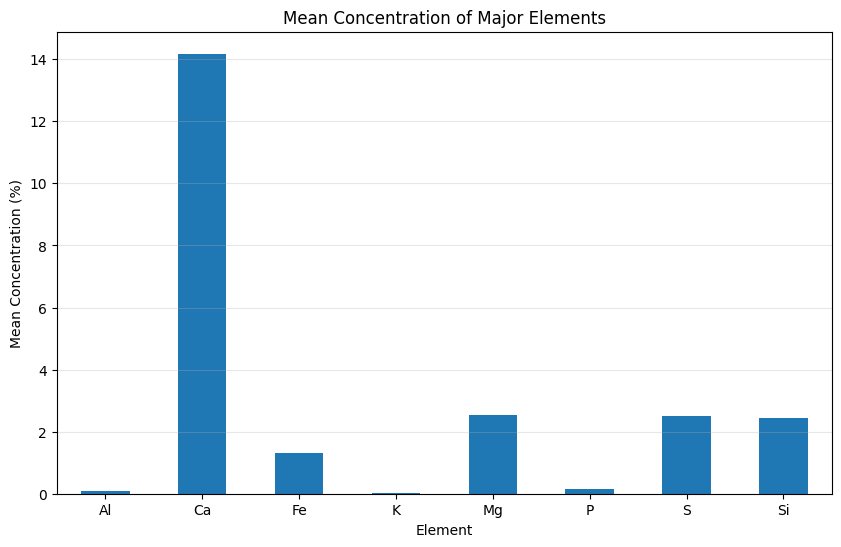

In [ ]:
mean_values = df_clean[major_elements].mean()

mean_values.index = [
    'Al', 'Ca', 'Fe', 'K', 'Mg', 'P', 'S', 'Si'
]

plt.figure(figsize=(10, 6))

mean_values.plot(kind='bar')

plt.title('Mean Concentration of Major Elements')
plt.xlabel('Element')
plt.ylabel('Mean Concentration (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

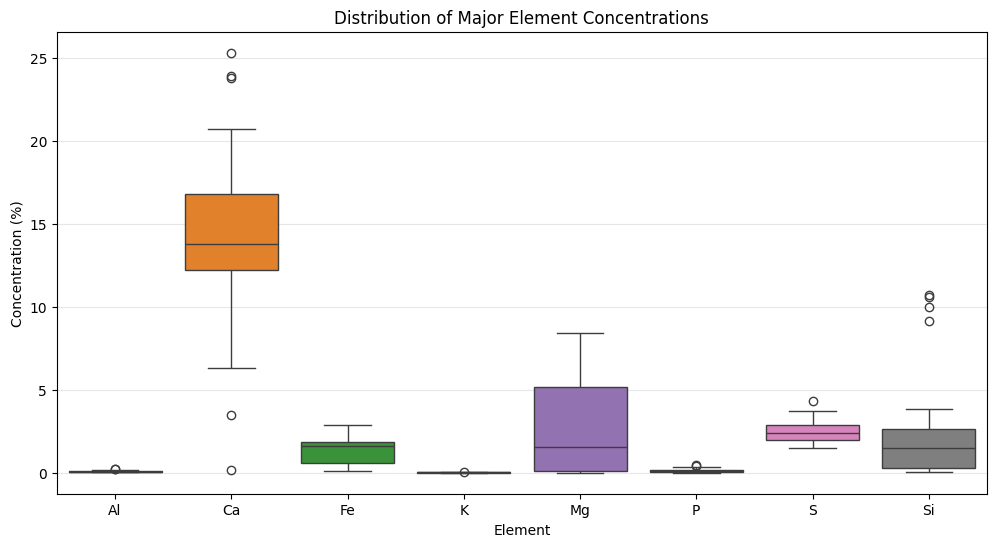

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_clean[major_elements])

plt.title('Distribution of Major Element Concentrations')
plt.xlabel('Element')
plt.ylabel('Concentration (%)')
plt.xticks(
    range(len(major_elements)),
    ['Al', 'Ca', 'Fe', 'K', 'Mg', 'P', 'S', 'Si']
)

plt.grid(axis='y', alpha=0.3)
plt.show()

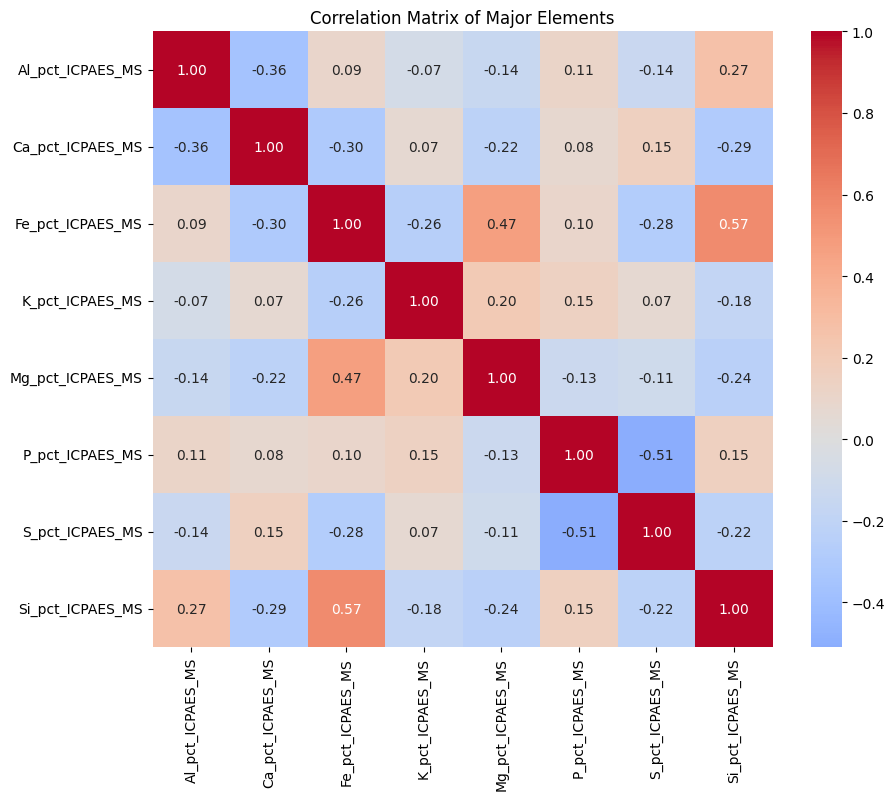

In [ ]:
correlation = df_clean[major_elements].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Major Elements")

plt.show()

In [ ]:
# Restore the original valid longitude values

df_clean['Longitude'] = df['Longitude']

print(df_clean['Longitude'].describe())

count      29.000000
mean    -1819.578586
std      3799.460630
min     -9999.000000
25%      -115.533300
50%      -115.532500
75%      -115.531700
max      -115.529400
Name: Longitude, dtype: float64


In [ ]:
# Restore original longitude
df_clean['Longitude'] = df['Longitude']

# Convert only the -9999 longitude codes to NaN
df_clean['Longitude'] = df_clean['Longitude'].replace(-9999, np.nan)

print(df_clean['Longitude'].describe())

count     24.000000
mean    -115.532458
std        0.001429
min     -115.536300
25%     -115.532725
50%     -115.532500
75%     -115.531700
max     -115.529400
Name: Longitude, dtype: float64


In [ ]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(15))

Dataset shape: (29, 85)

Missing values:
Cr2O3_pct_WDXRF     29
Te_ppm_ICPAES_MS    29
Tl_ppm_ICPAES_MS    29
V2O5_pct_WDXRF      29
In_ppm_ICPAES_MS    29
Ta_ppm_ICPAES_MS    28
TiO2_pct_WDXRF      28
Hf_ppm_ICPAES_MS    28
Ti_pct_ICPAES_MS    28
B_ppm_ICPAES_MS     26
Ag_ppm_ICPAES_MS    24
Cr_ppm_ICPAES_MS    23
Cs_ppm_ICPAES_MS    23
Se_ppm_ICPAES_MS    22
Sn_ppm_ICPAES_MS    22
dtype: int64


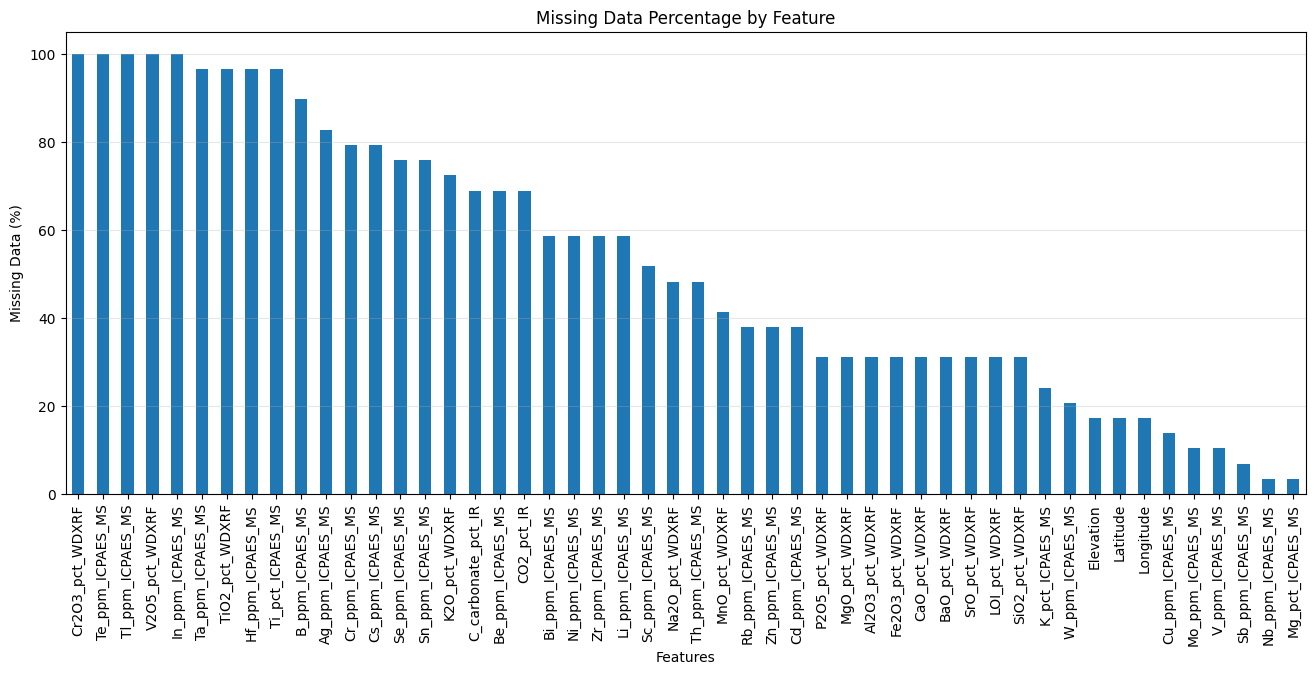

In [ ]:
missing_percent = (
    df_clean.isnull().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(16, 6))

missing_percent[missing_percent > 0].plot(kind='bar')

plt.title('Missing Data Percentage by Feature')
plt.xlabel('Features')
plt.ylabel('Missing Data (%)')
plt.xticks(rotation=90)

plt.grid(axis='y', alpha=0.3)
plt.show()

## 4. Feature Selection & Preprocessing

In [ ]:
feature_std = df_clean[chemical_features].std()

feature_std = feature_std.sort_values(ascending=False)

print(feature_std.head(15))

Sr_ppm_ICPAES_MS    32118.239485
Ce_ppm_ICPAES_MS    29777.327557
Ba_ppm_ICPAES_MS    23500.250497
La_ppm_ICPAES_MS    21378.184809
Nd_ppm_ICPAES_MS     7916.893563
Pr_ppm_ICPAES_MS     2690.609972
Mn_ppm_ICPAES_MS     2226.001011
Pb_ppm_ICPAES_MS     1509.808911
Sm_ppm_ICPAES_MS      623.629714
Gd_ppm_ICPAES_MS      193.182884
Th_ppm_ICPAES_MS      171.845529
Ga_ppm_ICPAES_MS      128.529344
Y_ppm_ICPAES_MS       119.212438
Eu_ppm_ICPAES_MS       96.208729
As_ppm_ICPAES_MS       58.774680
dtype: float64


In [ ]:
scale_summary = df_clean[chemical_features].agg(['min', 'max', 'mean', 'std']).T

scale_summary.sort_values('std', ascending=False).head(15)

,min,max,mean,std
Sr_ppm_ICPAES_MS,1420.0,119000.0,23568.275862,32118.239485
Ce_ppm_ICPAES_MS,11300.0,125000.0,47593.103448,29777.327557
Ba_ppm_ICPAES_MS,17000.0,114000.0,74496.551724,23500.250497
La_ppm_ICPAES_MS,7150.0,83900.0,33750.000000,21378.184809
Nd_ppm_ICPAES_MS,3000.0,35900.0,12404.137931,7916.893563
Pr_ppm_ICPAES_MS,1080.0,11400.0,4320.344828,2690.609972
Mn_ppm_ICPAES_MS,17.0,8790.0,3982.000000,2226.001011
Pb_ppm_ICPAES_MS,62.0,5000.0,1540.344828,1509.808911
Sm_ppm_ICPAES_MS,242.0,2840.0,835.655172,623.629714
Gd_ppm_ICPAES_MS,66.1,890.0,245.434483,193.182884


In [ ]:
print("Number of chemical features:", len(chemical_features))
print("\nChemical features:")
for i, feature in enumerate(chemical_features, 1):
    print(i, feature)

Number of chemical features: 54

Chemical features:
1 Al_pct_ICPAES_MS
2 Ca_pct_ICPAES_MS
3 Fe_pct_ICPAES_MS
4 K_pct_ICPAES_MS
5 Mg_pct_ICPAES_MS
6 P_pct_ICPAES_MS
7 S_pct_ICPAES_MS
8 Si_pct_ICPAES_MS
9 As_ppm_ICPAES_MS
10 Ba_ppm_ICPAES_MS
11 Cd_ppm_ICPAES_MS
12 Ce_ppm_ICPAES_MS
13 Co_ppm_ICPAES_MS
14 Cu_ppm_ICPAES_MS
15 Dy_ppm_ICPAES_MS
16 Er_ppm_ICPAES_MS
17 Eu_ppm_ICPAES_MS
18 Ga_ppm_ICPAES_MS
19 Gd_ppm_ICPAES_MS
20 Ge_ppm_ICPAES_MS
21 Ho_ppm_ICPAES_MS
22 La_ppm_ICPAES_MS
23 Lu_ppm_ICPAES_MS
24 Mn_ppm_ICPAES_MS
25 Mo_ppm_ICPAES_MS
26 Nb_ppm_ICPAES_MS
27 Nd_ppm_ICPAES_MS
28 Pb_ppm_ICPAES_MS
29 Pr_ppm_ICPAES_MS
30 Rb_ppm_ICPAES_MS
31 Sb_ppm_ICPAES_MS
32 Sm_ppm_ICPAES_MS
33 Sr_ppm_ICPAES_MS
34 Tb_ppm_ICPAES_MS
35 Th_ppm_ICPAES_MS
36 Tm_ppm_ICPAES_MS
37 U_ppm_ICPAES_MS
38 V_ppm_ICPAES_MS
39 W_ppm_ICPAES_MS
40 Y_ppm_ICPAES_MS
41 Yb_ppm_ICPAES_MS
42 Zn_ppm_ICPAES_MS
43 F_ppm_ISE
44 Al2O3_pct_WDXRF
45 BaO_pct_WDXRF
46 CaO_pct_WDXRF
47 Fe2O3_pct_WDXRF
48 MgO_pct_WDXRF
49 MnO_pct_WDXRF
50 Na

## 5. Principal Component Analysis (PCA)

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_imputed = imputer.fit_transform(df_clean[chemical_features])

print("Original shape:", df_clean[chemical_features].shape)
print("After imputation:", X_imputed.shape)
print("Remaining missing values:", np.isnan(X_imputed).sum())

Original shape: (29, 54)
After imputation: (29, 54)
Remaining missing values: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Scaled data shape:", X_scaled.shape)
print("Mean of scaled data:", X_scaled.mean())
print("Standard deviation of scaled data:", X_scaled.std())

Scaled data shape: (29, 54)
Mean of scaled data: -6.295517534272918e-17
Standard deviation of scaled data: 1.0


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X_scaled.shape)
print("PCA dimensions:", X_pca.shape)

Original dimensions: (29, 54)
PCA dimensions: (29, 29)


In [ ]:
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance, 1):
    print(f"PC{i}: {variance:.4f} ({variance*100:.2f}%)")

PC1: 0.3365 (33.65%)
PC2: 0.1412 (14.12%)
PC3: 0.1163 (11.63%)
PC4: 0.0707 (7.07%)
PC5: 0.0565 (5.65%)
PC6: 0.0513 (5.13%)
PC7: 0.0366 (3.66%)
PC8: 0.0302 (3.02%)
PC9: 0.0255 (2.55%)
PC10: 0.0252 (2.52%)
PC11: 0.0220 (2.20%)
PC12: 0.0182 (1.82%)
PC13: 0.0131 (1.31%)
PC14: 0.0108 (1.08%)
PC15: 0.0092 (0.92%)
PC16: 0.0071 (0.71%)
PC17: 0.0065 (0.65%)
PC18: 0.0053 (0.53%)
PC19: 0.0042 (0.42%)
PC20: 0.0030 (0.30%)
PC21: 0.0028 (0.28%)
PC22: 0.0022 (0.22%)
PC23: 0.0017 (0.17%)
PC24: 0.0012 (0.12%)
PC25: 0.0011 (0.11%)
PC26: 0.0009 (0.09%)
PC27: 0.0003 (0.03%)
PC28: 0.0003 (0.03%)
PC29: 0.0000 (0.00%)


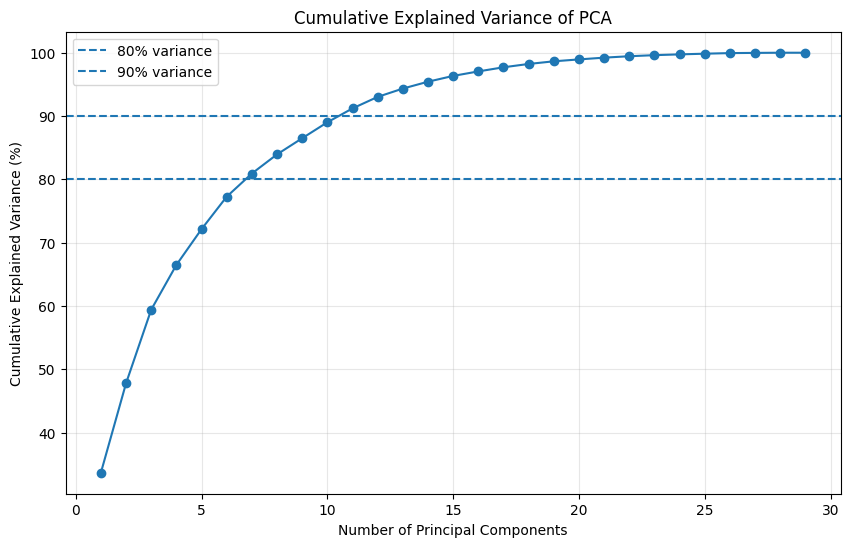

In [ ]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker='o'
)

plt.axhline(y=80, linestyle='--', label='80% variance')
plt.axhline(y=90, linestyle='--', label='90% variance')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('Cumulative Explained Variance of PCA')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for 90% variance:", n_components_90)
print(
    "Cumulative variance explained:",
    f"{cumulative_variance[n_components_90 - 1] * 100:.2f}%"
)

Components required for 90% variance: 11
Cumulative variance explained: 91.20%


In [ ]:
pca_11 = PCA(n_components=11)

X_pca_11 = pca_11.fit_transform(X_scaled)

print("Original data shape:", X_scaled.shape)
print("Reduced PCA data shape:", X_pca_11.shape)
print("Variance retained:",
      f"{pca_11.explained_variance_ratio_.sum() * 100:.2f}%")

Original data shape: (29, 54)
Reduced PCA data shape: (29, 11)
Variance retained: 91.20%


In [ ]:
pc1_loadings = pd.Series(
    pca_11.components_[0],
    index=chemical_features
)

pc1_loadings = pc1_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC1:")
print(pc1_loadings.head(10))

Top 10 features contributing to PC1:
Sm_ppm_ICPAES_MS    0.230562
Eu_ppm_ICPAES_MS    0.229469
Tb_ppm_ICPAES_MS    0.227831
Nd_ppm_ICPAES_MS    0.225303
Gd_ppm_ICPAES_MS    0.225189
Ge_ppm_ICPAES_MS    0.221085
Dy_ppm_ICPAES_MS    0.219846
Ho_ppm_ICPAES_MS    0.217120
Pr_ppm_ICPAES_MS    0.214444
Y_ppm_ICPAES_MS     0.213756
dtype: float64


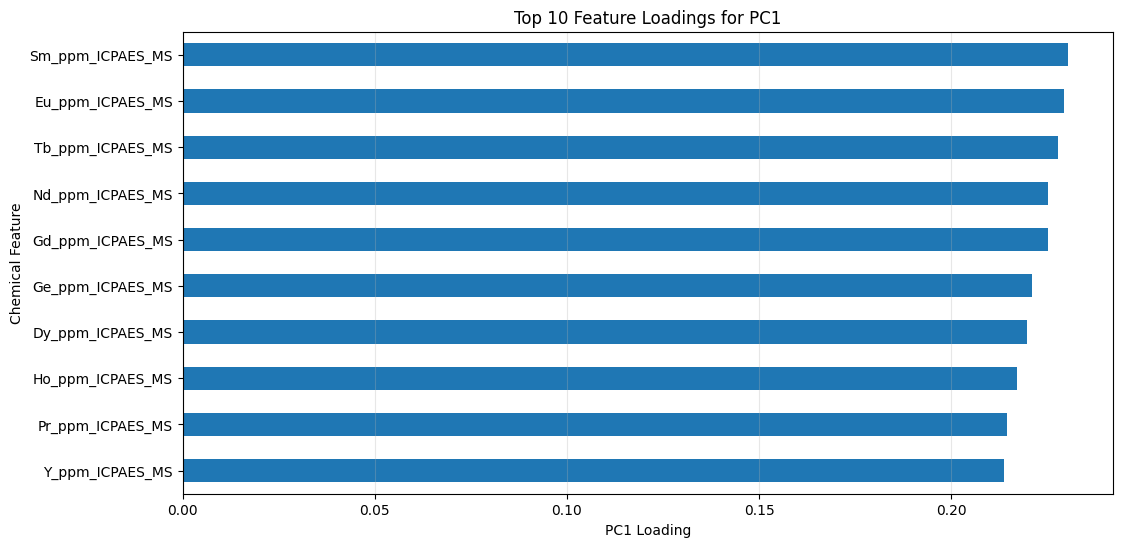

In [ ]:
plt.figure(figsize=(12, 6))

pc1_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC1')
plt.xlabel('PC1 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc2_loadings = pd.Series(
    pca_11.components_[1],
    index=chemical_features
)

pc2_loadings = pc2_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC2:")
print(pc2_loadings.head(10))

Top 10 features contributing to PC2:
Fe2O3_pct_WDXRF     0.286675
Fe_pct_ICPAES_MS    0.272448
W_ppm_ICPAES_MS     0.268476
MnO_pct_WDXRF       0.263685
SiO2_pct_WDXRF      0.253057
Mn_ppm_ICPAES_MS    0.235873
Si_pct_ICPAES_MS    0.226364
S_pct_ICPAES_MS    -0.208525
SrO_pct_WDXRF      -0.204747
Pb_ppm_ICPAES_MS    0.201750
dtype: float64


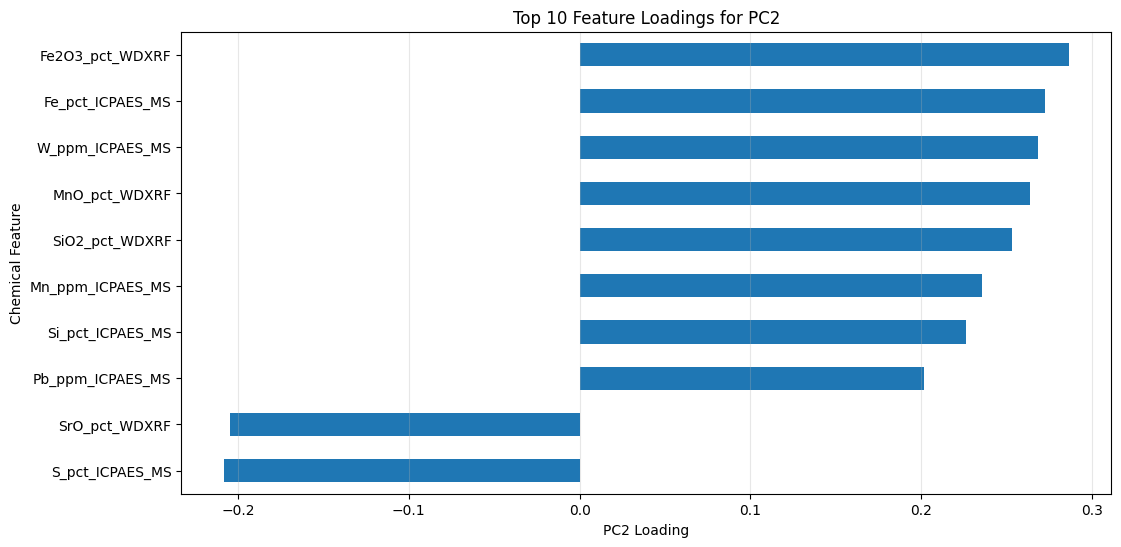

In [ ]:
plt.figure(figsize=(12, 6))

pc2_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC2')
plt.xlabel('PC2 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc3_loadings = pd.Series(
    pca_11.components_[2],
    index=chemical_features
)

pc3_loadings = pc3_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC3:")
print(pc3_loadings.head(10))

Top 10 features contributing to PC3:
BaO_pct_WDXRF       0.343304
LOI_pct_WDXRF      -0.253609
CaO_pct_WDXRF      -0.249576
K_pct_ICPAES_MS     0.213159
Yb_ppm_ICPAES_MS   -0.200071
Lu_ppm_ICPAES_MS   -0.199997
Rb_ppm_ICPAES_MS    0.183435
Th_ppm_ICPAES_MS    0.183090
V_ppm_ICPAES_MS     0.175002
Tm_ppm_ICPAES_MS   -0.172722
dtype: float64


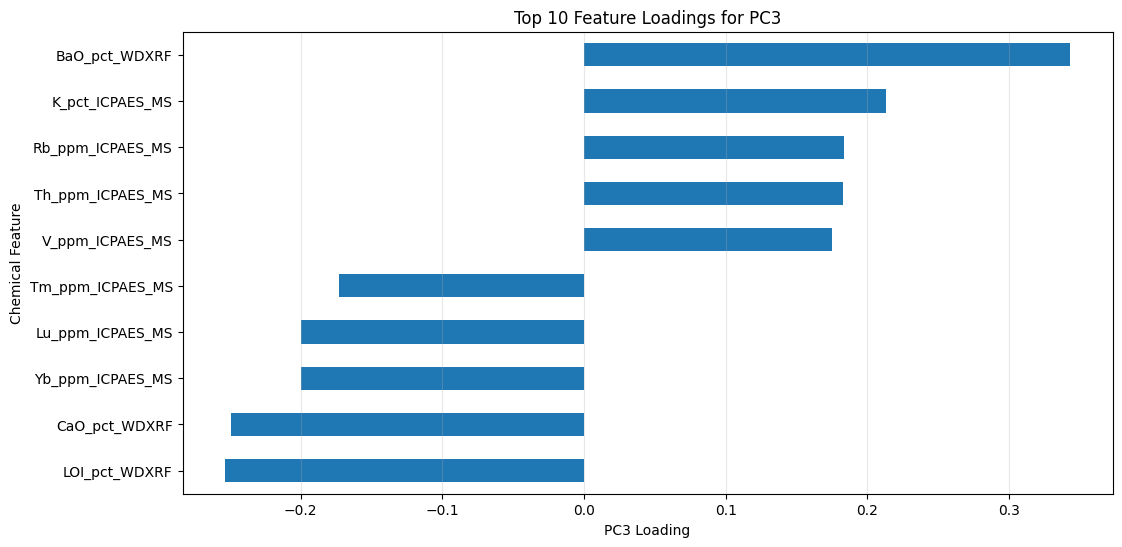

In [ ]:
plt.figure(figsize=(12, 6))

pc3_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC3')
plt.xlabel('PC3 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc4_loadings = pd.Series(
    pca_11.components_[3],
    index=chemical_features
)

pc4_loadings = pc4_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC4:")
print(pc4_loadings.head(10))

Top 10 features contributing to PC4:
Mg_pct_ICPAES_MS    0.371246
MgO_pct_WDXRF       0.326140
Pb_ppm_ICPAES_MS   -0.293719
Ba_ppm_ICPAES_MS    0.278179
Na2O_pct_WDXRF     -0.275786
Th_ppm_ICPAES_MS   -0.241932
Rb_ppm_ICPAES_MS   -0.224596
SiO2_pct_WDXRF     -0.190627
CaO_pct_WDXRF      -0.185150
W_ppm_ICPAES_MS    -0.177976
dtype: float64


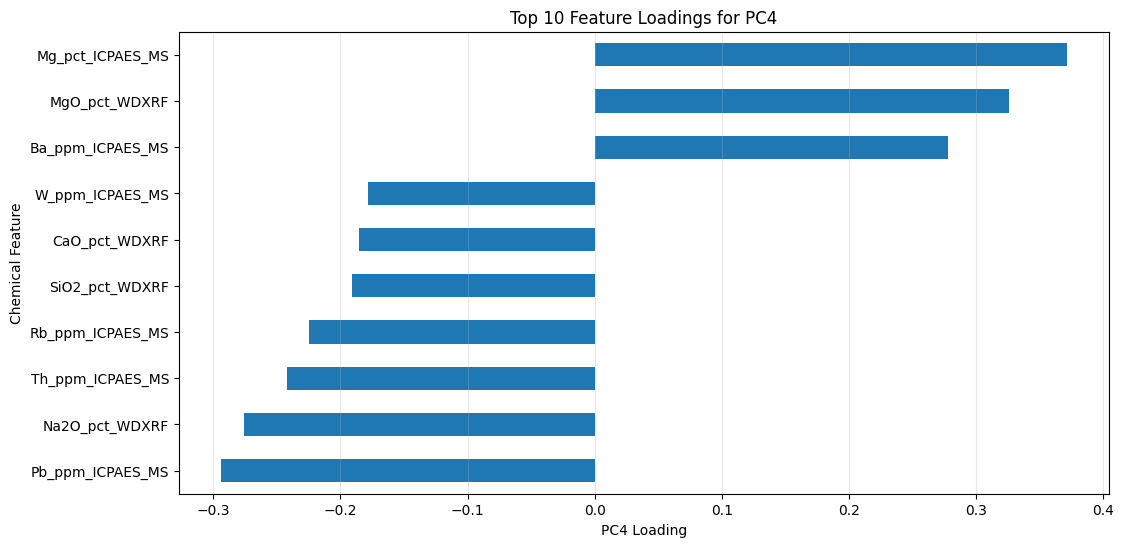

In [ ]:
plt.figure(figsize=(12, 6))

pc4_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC4')
plt.xlabel('PC4 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc5_loadings = pd.Series(
    pca_11.components_[4],
    index=chemical_features
)

pc5_loadings = pc5_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC5:")
print(pc5_loadings.head(10))

Top 10 features contributing to PC5:
Nb_ppm_ICPAES_MS    0.377591
P_pct_ICPAES_MS     0.337624
P2O5_pct_WDXRF      0.304691
LOI_pct_WDXRF       0.290118
SiO2_pct_WDXRF     -0.257388
V_ppm_ICPAES_MS    -0.232320
CaO_pct_WDXRF       0.228285
S_pct_ICPAES_MS    -0.226812
Ca_pct_ICPAES_MS    0.210063
Sr_ppm_ICPAES_MS   -0.168458
dtype: float64


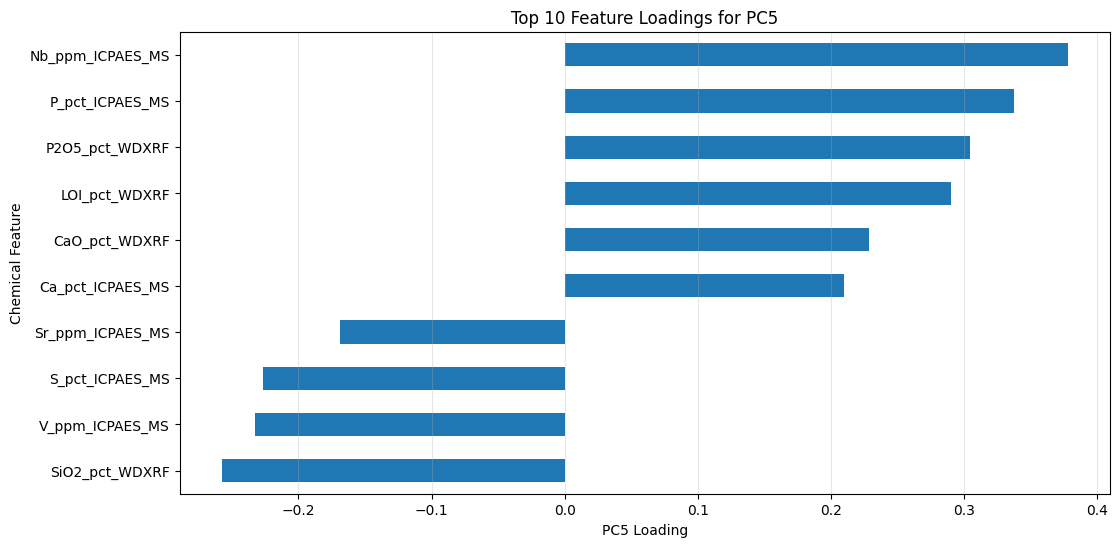

In [ ]:
plt.figure(figsize=(12, 6))

pc5_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC5')
plt.xlabel('PC5 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc6_loadings = pd.Series(
    pca_11.components_[5],
    index=chemical_features
)

pc6_loadings = pc6_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC6:")
print(pc6_loadings.head(10))

Top 10 features contributing to PC6:
Al_pct_ICPAES_MS    0.369216
Sr_ppm_ICPAES_MS    0.360120
SrO_pct_WDXRF       0.358221
Al2O3_pct_WDXRF     0.253215
As_ppm_ICPAES_MS    0.237515
Sb_ppm_ICPAES_MS    0.221617
Th_ppm_ICPAES_MS   -0.209363
Ba_ppm_ICPAES_MS   -0.207603
Cd_ppm_ICPAES_MS   -0.205363
MnO_pct_WDXRF       0.173233
dtype: float64


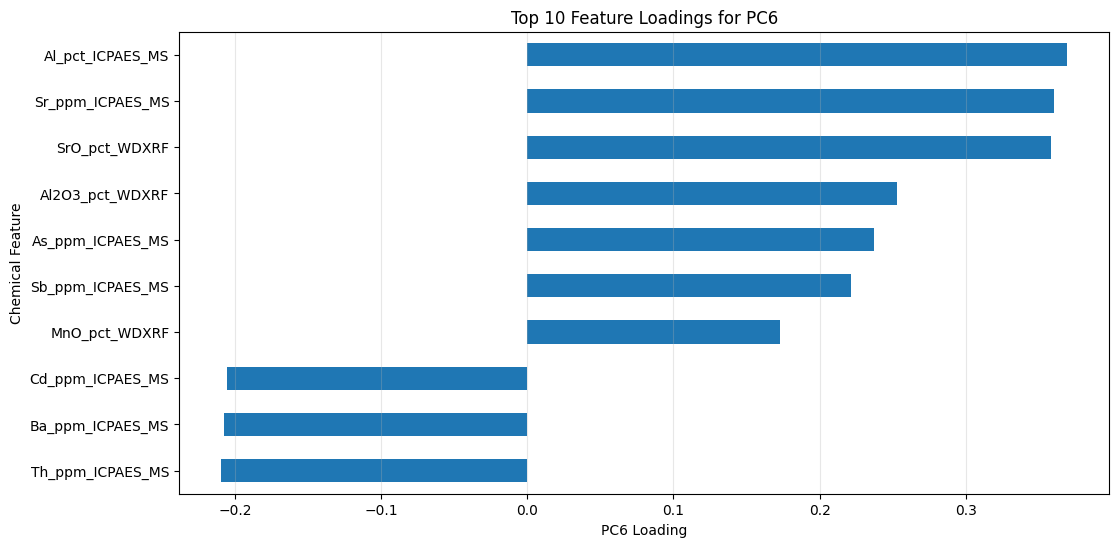

In [ ]:
plt.figure(figsize=(12, 6))

pc6_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC6')
plt.xlabel('PC6 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc7_loadings = pd.Series(
    pca_11.components_[6],
    index=chemical_features
)

pc7_loadings = pc7_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC7:")
print(pc7_loadings.head(10))

Top 10 features contributing to PC7:
W_ppm_ICPAES_MS     0.303775
Zn_ppm_ICPAES_MS   -0.300725
As_ppm_ICPAES_MS    0.252276
Rb_ppm_ICPAES_MS   -0.249291
Al2O3_pct_WDXRF    -0.236174
Nb_ppm_ICPAES_MS   -0.233285
P_pct_ICPAES_MS     0.227677
U_ppm_ICPAES_MS    -0.210741
Th_ppm_ICPAES_MS   -0.204501
Ba_ppm_ICPAES_MS    0.192847
dtype: float64


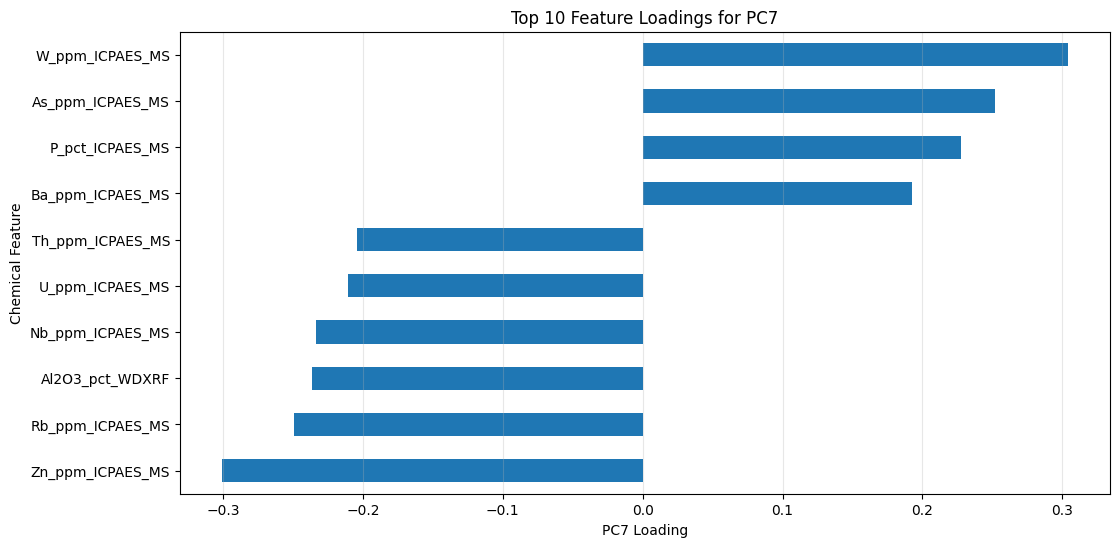

In [ ]:
plt.figure(figsize=(12, 6))

pc7_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC7')
plt.xlabel('PC7 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc8_loadings = pd.Series(
    pca_11.components_[7],
    index=chemical_features
)

pc8_loadings = pc8_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC8:")
print(pc8_loadings.head(10))

Top 10 features contributing to PC8:
Cu_ppm_ICPAES_MS    0.503949
Al2O3_pct_WDXRF    -0.402150
Sb_ppm_ICPAES_MS    0.355428
Nb_ppm_ICPAES_MS    0.263542
S_pct_ICPAES_MS     0.237331
Al_pct_ICPAES_MS   -0.228655
U_ppm_ICPAES_MS     0.228348
P2O5_pct_WDXRF     -0.174172
Na2O_pct_WDXRF     -0.146828
CaO_pct_WDXRF      -0.144389
dtype: float64


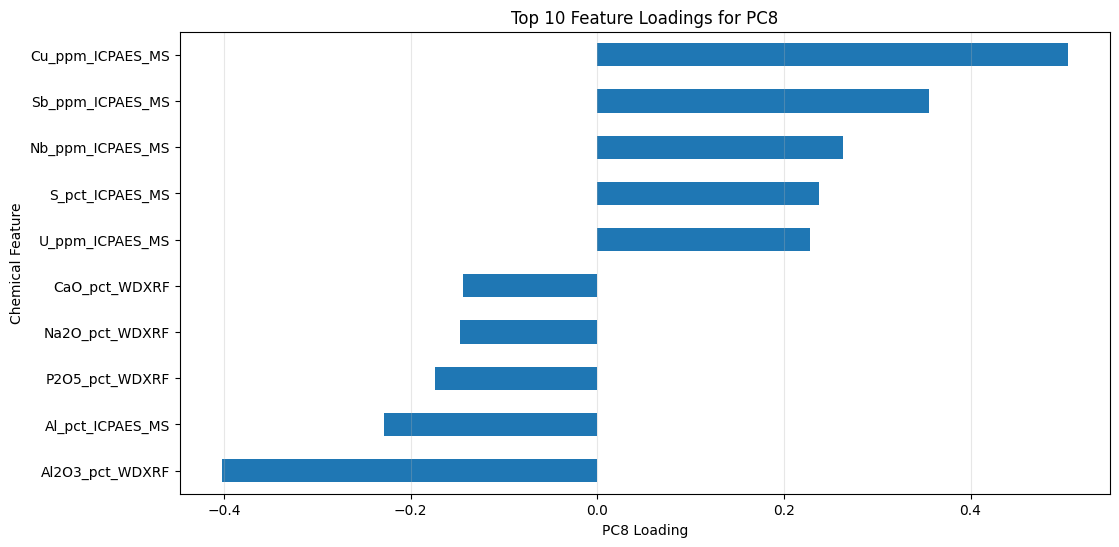

In [ ]:
plt.figure(figsize=(12, 6))

pc8_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC8')
plt.xlabel('PC8 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc9_loadings = pd.Series(
    pca_11.components_[8],
    index=chemical_features
)

pc9_loadings = pc9_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC9:")
print(pc9_loadings.head(10))

Top 10 features contributing to PC9:
K_pct_ICPAES_MS     0.430947
Cd_ppm_ICPAES_MS    0.379292
MnO_pct_WDXRF       0.342029
Co_ppm_ICPAES_MS   -0.309948
BaO_pct_WDXRF      -0.262477
Na2O_pct_WDXRF     -0.249189
LOI_pct_WDXRF       0.224494
Ba_ppm_ICPAES_MS    0.190356
Mo_ppm_ICPAES_MS   -0.165486
Ca_pct_ICPAES_MS    0.139241
dtype: float64


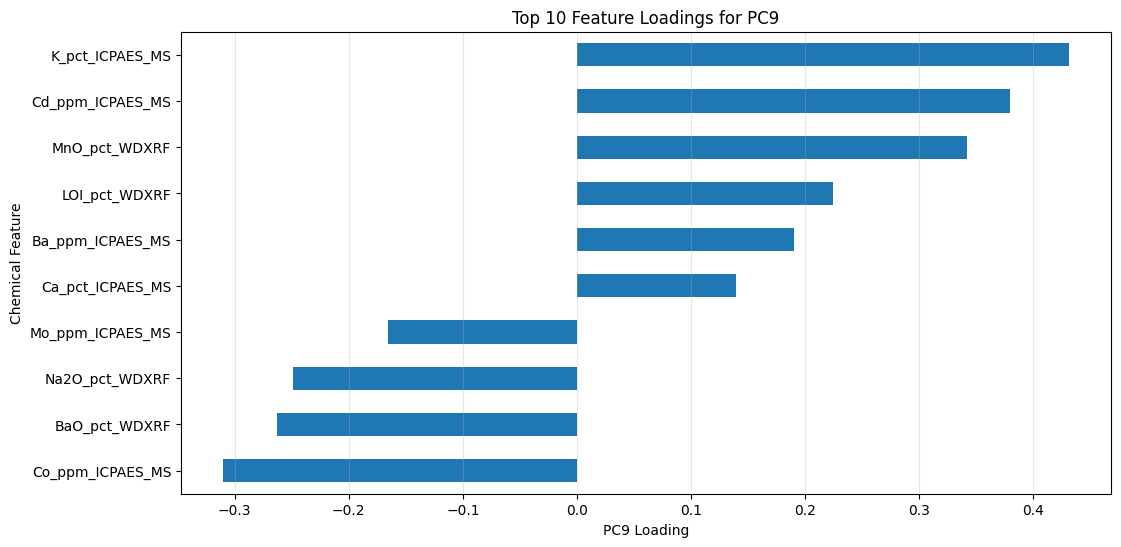

In [ ]:
plt.figure(figsize=(12, 6))

pc9_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC9')
plt.xlabel('PC9 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc10_loadings = pd.Series(
    pca_11.components_[9],
    index=chemical_features
)

pc10_loadings = pc10_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC10:")
print(pc10_loadings.head(10))

Top 10 features contributing to PC10:
Mo_ppm_ICPAES_MS    0.417249
Zn_ppm_ICPAES_MS    0.314405
Ba_ppm_ICPAES_MS   -0.288472
MgO_pct_WDXRF       0.264730
S_pct_ICPAES_MS    -0.243494
Mn_ppm_ICPAES_MS   -0.216525
Na2O_pct_WDXRF     -0.210695
LOI_pct_WDXRF       0.177956
Rb_ppm_ICPAES_MS   -0.171359
Cd_ppm_ICPAES_MS    0.165571
dtype: float64


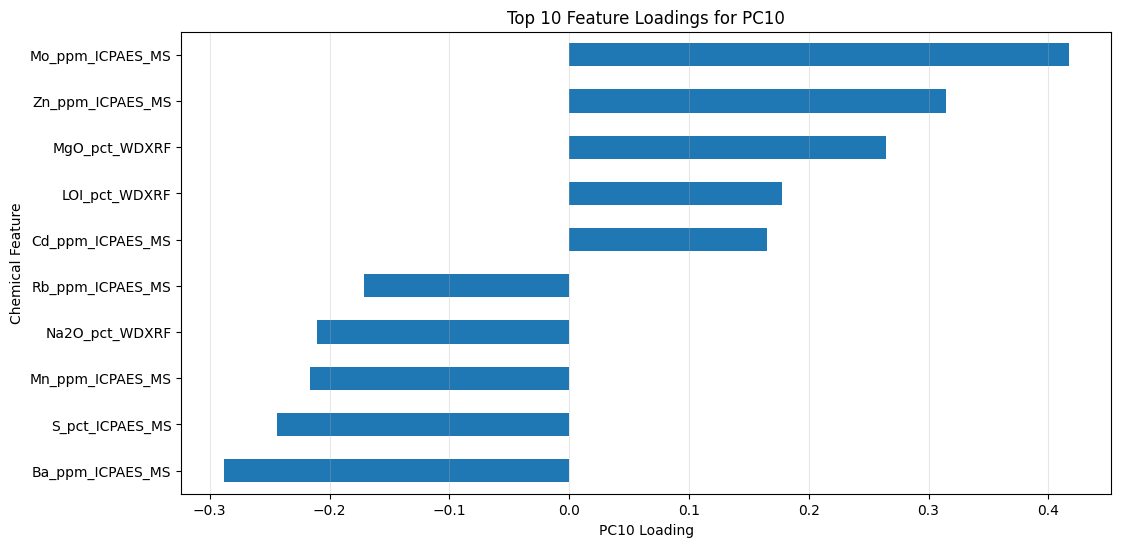

In [ ]:
plt.figure(figsize=(12, 6))

pc10_loadings.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Loadings for PC10')
plt.xlabel('PC10 Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [ ]:
pc11_loadings = pd.Series(
    pca_11.components_[10],
    index=chemical_features
)

pc11_loadings = pc11_loadings.sort_values(
    key=abs,
    ascending=False
)

print("Top 10 features contributing to PC11:")
print(pc11_loadings.head(10))

Top 10 features contributing to PC11:
Mo_ppm_ICPAES_MS    0.353145
Al_pct_ICPAES_MS    0.314776
Sb_ppm_ICPAES_MS   -0.300743
Na2O_pct_WDXRF     -0.285593
Ba_ppm_ICPAES_MS    0.261815
V_ppm_ICPAES_MS    -0.259720
Cu_ppm_ICPAES_MS    0.242247
Si_pct_ICPAES_MS    0.226517
P2O5_pct_WDXRF     -0.225193
Cd_ppm_ICPAES_MS   -0.215076
dtype: float64


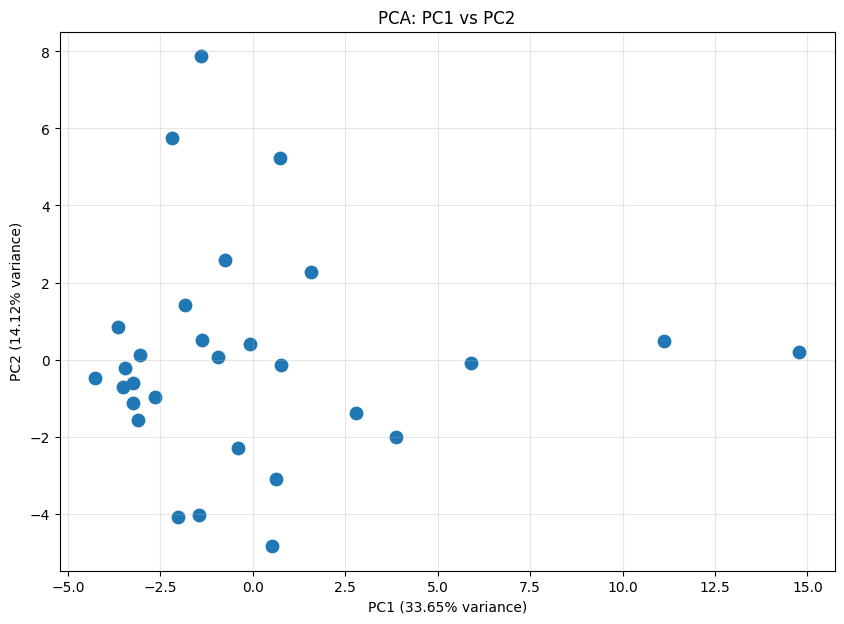

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca_11[:, 0],
    X_pca_11[:, 1],
    s=80
)

plt.xlabel('PC1 (33.65% variance)')
plt.ylabel('PC2 (14.12% variance)')
plt.title('PCA: PC1 vs PC2')
plt.grid(alpha=0.3)
plt.show()

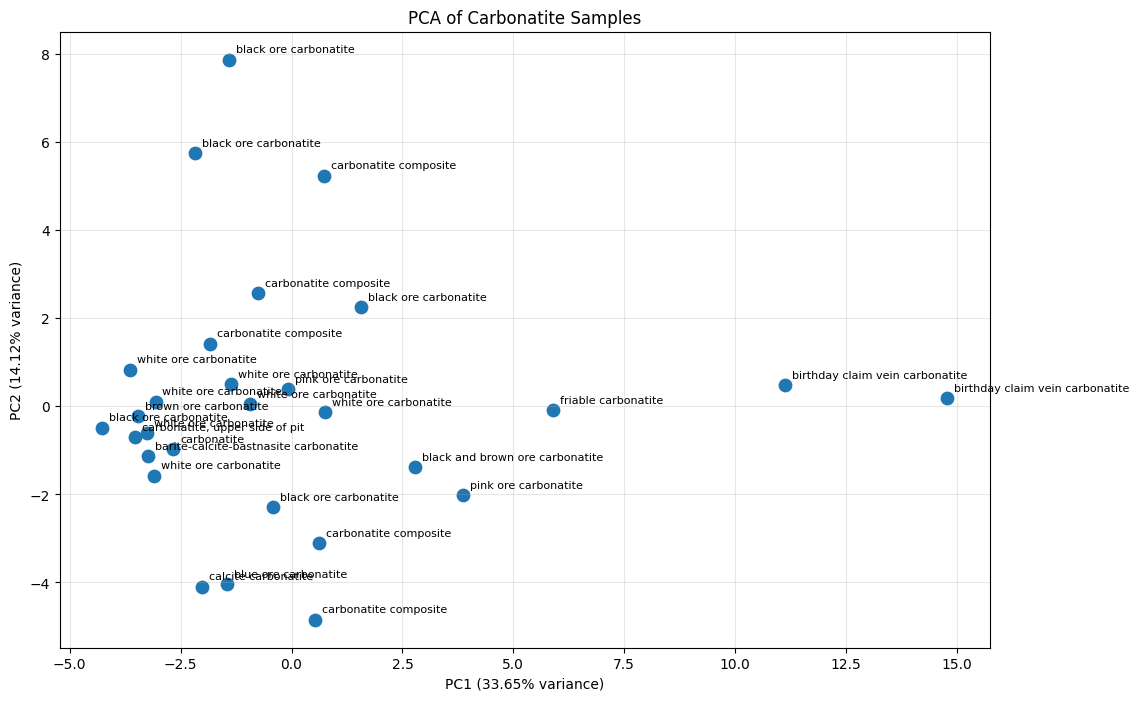

In [ ]:
plt.figure(figsize=(12, 8))

plt.scatter(
    X_pca_11[:, 0],
    X_pca_11[:, 1],
    s=80
)

for i, label in enumerate(df_clean['Description']):
    plt.annotate(
        label,
        (X_pca_11[i, 0], X_pca_11[i, 1]),
        fontsize=8,
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel('PC1 (33.65% variance)')
plt.ylabel('PC2 (14.12% variance)')
plt.title('PCA of Carbonatite Samples')
plt.grid(alpha=0.3)
plt.show()

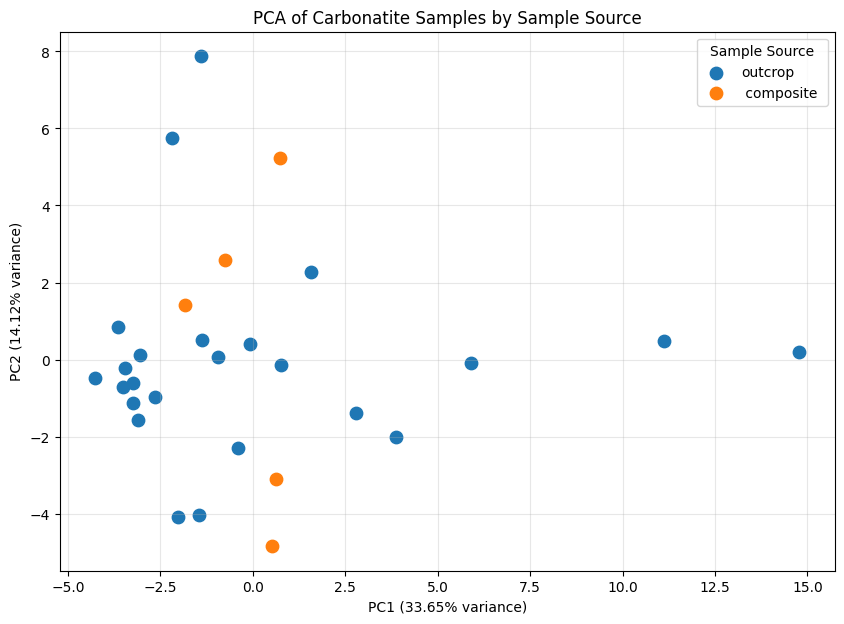

In [ ]:
plt.figure(figsize=(10, 7))

sources = df_clean['Sample_source'].str.lower()

for source in sources.unique():
    mask = sources == source

    plt.scatter(
        X_pca_11[mask, 0],
        X_pca_11[mask, 1],
        s=80,
        label=source
    )

plt.xlabel('PC1 (33.65% variance)')
plt.ylabel('PC2 (14.12% variance)')
plt.title('PCA of Carbonatite Samples by Sample Source')
plt.legend(title='Sample Source')
plt.grid(alpha=0.3)
plt.show()

In [ ]:
pca_df = pd.DataFrame(
    X_pca_11,
    columns=[f'PC{i}' for i in range(1, 12)]
)

pca_df['Description'] = df_clean['Description'].values
pca_df['Sample_source'] = df_clean['Sample_source'].values

print("PCA results shape:", pca_df.shape)

pca_df.head()

PCA results shape: (29, 13)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,Description,Sample_source
0,-3.523451,-0.707346,-0.313305,-4.042839,4.369968,-1.858531,-1.076645,-1.716099,-1.149478,0.434853,0.086333,"carbonatite, upper side of pit",outcrop
1,-1.449326,-4.043048,-3.063869,-2.834234,-1.980170,2.473419,-0.469613,-0.818733,-1.154327,-0.957938,-1.920479,blue ore carbonatite,outcrop
2,-0.413778,-2.296460,1.872792,-0.882090,-0.818260,-0.324574,1.053166,-0.077814,-0.199975,0.866813,-0.288530,black ore carbonatite,outcrop
3,-0.931711,0.054415,-1.391302,-0.160659,2.119467,-1.095301,0.102526,-0.285015,1.402072,1.719363,-1.507977,white ore carbonatite,outcrop
4,-1.405598,7.876000,-0.086508,-4.549615,-1.713457,-1.136289,-2.714221,0.843227,0.616576,1.026175,-0.515000,black ore carbonatite,outcrop


## 6. K-Means Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

# Use the 11 PCA components
for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_k = kmeans.fit_predict(X_pca_11)   # temporary labels for this K only
    score = silhouette_score(X_pca_11, labels_k)

    silhouette_scores[k] = score

for k, score in silhouette_scores.items():
    print(f"k = {k}: Silhouette Score = {score:.4f}")

k = 2: Silhouette Score = 0.4843
k = 3: Silhouette Score = 0.2982
k = 4: Silhouette Score = 0.2098
k = 5: Silhouette Score = 0.2230
k = 6: Silhouette Score = 0.2442


In [ ]:
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_pca_11)

pca_df['Cluster'] = cluster_labels

print("Cluster distribution:")
print(pca_df['Cluster'].value_counts().sort_index())

Cluster distribution:
Cluster
0     2
1    27
Name: count, dtype: int64


## 7. Results, Validation & Interpretation

In [ ]:
cluster_summary = pca_df[
    ['Description', 'Sample_source', 'PC1', 'PC2', 'Cluster']
].sort_values('Cluster')

cluster_summary

,Description,Sample_source,PC1,PC2,Cluster
10,birthday claim vein carbonatite,outcrop,11.123777,0.479384,0
20,birthday claim vein carbonatite,outcrop,14.782367,0.192601,0
2,black ore carbonatite,outcrop,-0.413778,-2.296460,1
0,"carbonatite, upper side of pit",outcrop,-3.523451,-0.707346,1
4,black ore carbonatite,outcrop,-1.405598,7.876000,1
5,friable carbonatite,outcrop,5.900508,-0.082940,1
6,white ore carbonatite,outcrop,0.760744,-0.129691,1
1,blue ore carbonatite,outcrop,-1.449326,-4.043048,1
7,white ore carbonatite,outcrop,-3.645860,0.833208,1
8,black ore carbonatite,outcrop,-2.183926,5.752152,1


In [ ]:
cluster_means = df_clean[chemical_features].copy()

cluster_means['Cluster'] = cluster_labels

cluster_mean_values = cluster_means.groupby('Cluster').mean().T

cluster_mean_values['Absolute_Difference'] = (
    cluster_mean_values[0] - cluster_mean_values[1]
).abs()

cluster_mean_values = cluster_mean_values.sort_values(
    'Absolute_Difference',
    ascending=False
)

cluster_mean_values.head(15)

Cluster,0,1,Absolute_Difference
Ce_ppm_ICPAES_MS,103250.0,43470.370370,59779.629630
La_ppm_ICPAES_MS,68900.0,31146.296296,37753.703704
Sr_ppm_ICPAES_MS,2275.0,25145.555556,22870.555556
Nd_ppm_ICPAES_MS,31950.0,10956.296296,20993.703704
Ba_ppm_ICPAES_MS,89600.0,73377.777778,16222.222222
Pr_ppm_ICPAES_MS,10005.0,3899.259259,6105.740741
Sm_ppm_ICPAES_MS,2760.0,693.111111,2066.888889
Pb_ppm_ICPAES_MS,205.5,1639.222222,1433.722222
Mn_ppm_ICPAES_MS,2855.0,4065.481481,1210.481481
Gd_ppm_ICPAES_MS,875.5,198.762963,676.737037


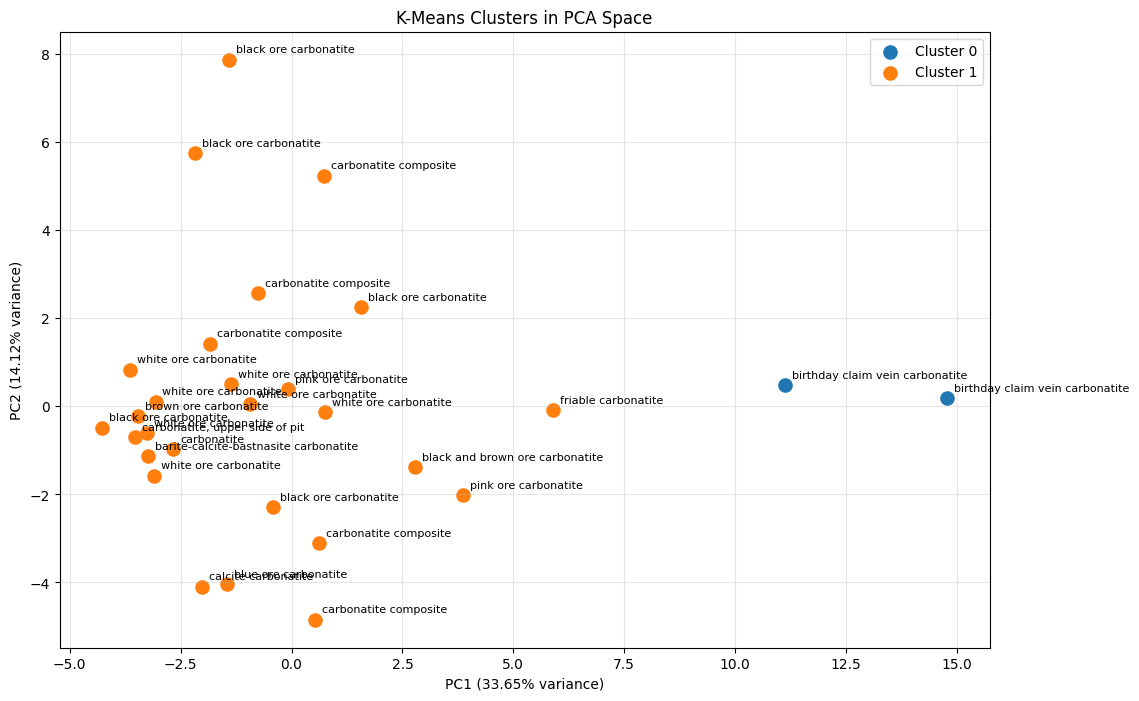

In [ ]:
plt.figure(figsize=(12, 8))

for cluster in sorted(pca_df['Cluster'].unique()):
    mask = pca_df['Cluster'] == cluster

    plt.scatter(
        X_pca_11[mask, 0],
        X_pca_11[mask, 1],
        s=90,
        label=f'Cluster {cluster}'
    )

for i, label in enumerate(df_clean['Description']):
    plt.annotate(
        label,
        (X_pca_11[i, 0], X_pca_11[i, 1]),
        fontsize=8,
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel('PC1 (33.65% variance)')
plt.ylabel('PC2 (14.12% variance)')
plt.title('K-Means Clusters in PCA Space')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
pca_summary = pd.DataFrame({
    'Component': [f'PC{i}' for i in range(1, 12)],
    'Explained_Variance_%': pca_11.explained_variance_ratio_ * 100,
    'Cumulative_Variance_%': np.cumsum(
        pca_11.explained_variance_ratio_
    ) * 100
})

pca_summary

,Component,Explained_Variance_%,Cumulative_Variance_%
0,PC1,33.653231,33.653231
1,PC2,14.124332,47.777563
2,PC3,11.626924,59.404487
3,PC4,7.070796,66.475283
4,PC5,5.652295,72.127578
5,PC6,5.129230,77.256808
6,PC7,3.659679,80.916487
7,PC8,3.023059,83.939546
8,PC9,2.550723,86.490270
9,PC10,2.518015,89.008285


In [ ]:
loading_matrix = pd.DataFrame(
    pca_11.components_.T,
    index=chemical_features,
    columns=[f'PC{i}' for i in range(1, 12)]
)

loading_matrix

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
Al_pct_ICPAES_MS,0.123857,0.049466,-0.012166,-0.005268,0.117732,0.369216,-0.064820,-0.228655,0.095077,0.023795,0.314776
Ca_pct_ICPAES_MS,-0.130713,-0.092824,-0.147053,-0.177689,0.210063,-0.170080,0.084975,-0.097692,0.139241,-0.002645,0.050303
Fe_pct_ICPAES_MS,0.004546,0.272448,-0.166496,0.136420,-0.123312,0.070068,0.060178,-0.048898,-0.102130,-0.123185,-0.120962
K_pct_ICPAES_MS,-0.082813,0.007499,0.213159,-0.078482,-0.064645,-0.028913,-0.130366,-0.020312,0.430947,-0.156752,0.174144
Mg_pct_ICPAES_MS,-0.092559,0.079165,-0.032191,0.371246,-0.005353,0.027577,-0.189553,-0.073363,-0.008574,-0.154159,-0.123724
P_pct_ICPAES_MS,-0.015922,0.174584,0.144592,-0.109325,0.337624,0.064278,0.227677,0.015946,-0.109002,0.045167,-0.098070
S_pct_ICPAES_MS,-0.038368,-0.208525,-0.087907,-0.029487,-0.226812,0.126049,0.056164,0.237331,0.073190,-0.243494,0.077239
Si_pct_ICPAES_MS,0.089164,0.226364,-0.119288,-0.156523,-0.111200,-0.006165,0.108419,0.129311,-0.116665,-0.027306,0.226517
As_ppm_ICPAES_MS,0.144783,0.155491,0.023721,-0.093361,0.072129,0.237515,0.252276,-0.061689,0.002215,-0.014114,0.084711
Ba_ppm_ICPAES_MS,0.026100,0.120826,0.045688,0.278179,0.029080,-0.207603,0.192847,0.119080,0.190356,-0.288472,0.261815


In [ ]:
overall_importance = loading_matrix.abs().max(axis=1)

overall_importance = overall_importance.sort_values(
    ascending=False
)

print("Top 15 features across all 11 PCs:")
print(overall_importance.head(15))

Top 15 features across all 11 PCs:
Cu_ppm_ICPAES_MS    0.503949
K_pct_ICPAES_MS     0.430947
Mo_ppm_ICPAES_MS    0.417249
Al2O3_pct_WDXRF     0.402150
Cd_ppm_ICPAES_MS    0.379292
Nb_ppm_ICPAES_MS    0.377591
Mg_pct_ICPAES_MS    0.371246
Al_pct_ICPAES_MS    0.369216
Sr_ppm_ICPAES_MS    0.360120
SrO_pct_WDXRF       0.358221
Sb_ppm_ICPAES_MS    0.355428
BaO_pct_WDXRF       0.343304
MnO_pct_WDXRF       0.342029
P_pct_ICPAES_MS     0.337624
MgO_pct_WDXRF       0.326140
dtype: float64


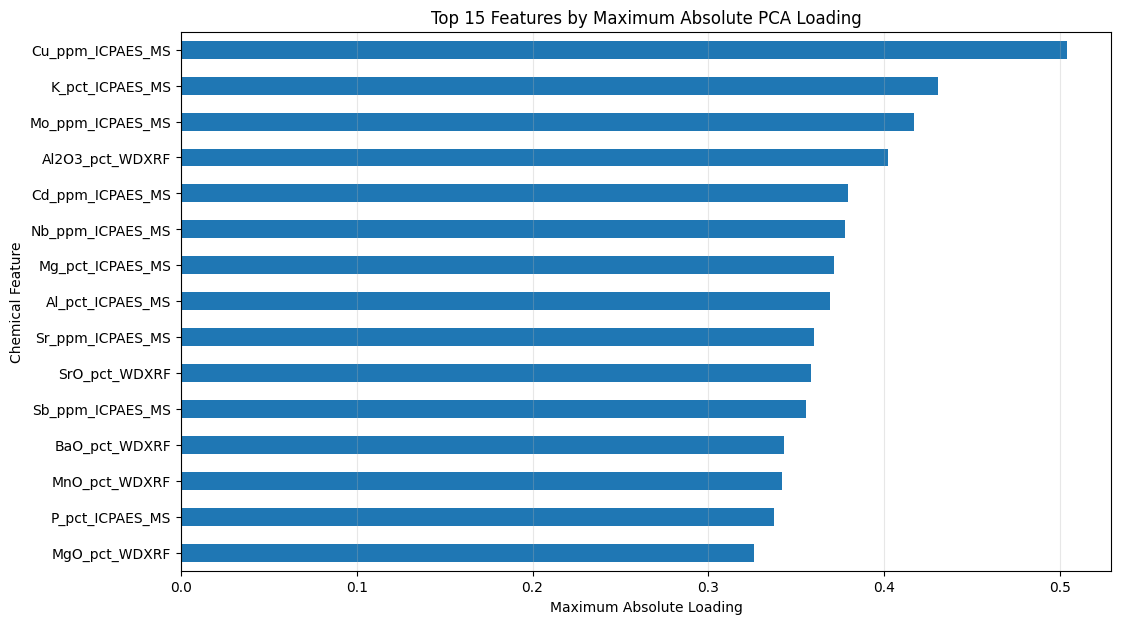

In [ ]:
top_features = overall_importance.head(15).sort_values()

plt.figure(figsize=(12, 7))

top_features.plot(kind='barh')

plt.title('Top 15 Features by Maximum Absolute PCA Loading')
plt.xlabel('Maximum Absolute Loading')
plt.ylabel('Chemical Feature')
plt.grid(axis='x', alpha=0.3)

plt.show()

In [ ]:
final_results = pca_df.copy()

final_results.to_csv(
    'carbonatite_PCA_cluster_results.csv',
    index=False
)

print("File saved successfully.")
print("Shape:", final_results.shape)

File saved successfully.
Shape: (29, 14)


In [ ]:
print("Final dataset shape:", final_results.shape)
print("Missing values:", final_results.isnull().sum().sum())
print("\nColumns:")
print(final_results.columns.tolist())

Final dataset shape: (29, 14)
Missing values: 0

Columns:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'Description', 'Sample_source', 'Cluster']


In [ ]:
print("Duplicate complete rows:", df_clean.duplicated().sum())

print("Duplicate Lab numbers:", df_clean['Lab_number'].duplicated().sum())

print("Duplicate Field IDs:", df_clean['Field_ID'].duplicated().sum())

Duplicate complete rows: 0
Duplicate Lab numbers: 0
Duplicate Field IDs: 0


In [ ]:
print("Description values:")
print(df_clean['Description'].value_counts())

print("\nSample source values:")
print(df_clean['Sample_source'].value_counts())

print("\nField ID count:", df_clean['Field_ID'].nunique())
print("Lab number count:", df_clean['Lab_number'].nunique())

Description values:
Description
white ore carbonatite                    7
black ore carbonatite                    5
carbonatite composite                    5
pink ore carbonatite                     2
birthday claim vein carbonatite          2
friable carbonatite                      1
blue ore carbonatite                     1
carbonatite, upper side of pit           1
brown ore carbonatite                    1
black and brown ore carbonatite          1
calcite carbonatite                      1
barite-calcite-bastnasite carbonatite    1
carbonatite                              1
Name: count, dtype: int64

Sample source values:
Sample_source
outcrop        24
 composite      5
Name: count, dtype: int64

Field ID count: 29
Lab number count: 29


In [ ]:
# Step 75: Outlier audit using IQR

outlier_summary = []

for col in chemical_features:
    series = df_clean[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = series[(series < lower) | (series > upper)]

    outlier_summary.append({
        'Feature': col,
        'Valid_values': len(series),
        'Outlier_count': len(outliers),
        'Outlier_%': round(len(outliers) / len(series) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df = outlier_df.sort_values(
    'Outlier_count',
    ascending=False
)

print(outlier_df.head(20))

             Feature  Valid_values  Outlier_count  Outlier_%
32  Sr_ppm_ICPAES_MS            29              6      20.69
1   Ca_pct_ICPAES_MS            29              5      17.24
38   W_ppm_ICPAES_MS            23              4      17.39
7   Si_pct_ICPAES_MS            29              4      13.79
8   As_ppm_ICPAES_MS            29              3      10.34
45     CaO_pct_WDXRF            20              3      15.00
26  Nd_ppm_ICPAES_MS            29              3      10.34
16  Eu_ppm_ICPAES_MS            29              2       6.90
14  Dy_ppm_ICPAES_MS            29              2       6.90
20  Ho_ppm_ICPAES_MS            29              2       6.90
18  Gd_ppm_ICPAES_MS            29              2       6.90
42         F_ppm_ISE            29              2       6.90
51    SiO2_pct_WDXRF            20              2      10.00
35  Tm_ppm_ICPAES_MS            29              2       6.90
22  Lu_ppm_ICPAES_MS            29              2       6.90
27  Pb_ppm_ICPAES_MS    

In [ ]:
# Step 76: Check skewness of chemical features

skewness = df_clean[chemical_features].skew().sort_values(ascending=False)

print("Most positively skewed features:")
print(skewness.head(15))

print("\nMost negatively skewed features:")
print(skewness.tail(10))

Most positively skewed features:
Lu_ppm_ICPAES_MS    3.143894
Yb_ppm_ICPAES_MS    3.046971
Tm_ppm_ICPAES_MS    2.963572
Er_ppm_ICPAES_MS    2.902276
Dy_ppm_ICPAES_MS    2.867523
Ho_ppm_ICPAES_MS    2.852835
Y_ppm_ICPAES_MS     2.691306
Na2O_pct_WDXRF      2.573148
Gd_ppm_ICPAES_MS    2.535852
Tb_ppm_ICPAES_MS    2.335221
W_ppm_ICPAES_MS     2.268940
Eu_ppm_ICPAES_MS    2.226315
Sm_ppm_ICPAES_MS    2.186779
SiO2_pct_WDXRF      2.118376
Nb_ppm_ICPAES_MS    2.040692
dtype: float64

Most negatively skewed features:
Mg_pct_ICPAES_MS    0.712645
Mn_ppm_ICPAES_MS    0.372986
MnO_pct_WDXRF       0.329768
Fe2O3_pct_WDXRF     0.306246
K_pct_ICPAES_MS     0.268465
Fe_pct_ICPAES_MS    0.033201
Ca_pct_ICPAES_MS   -0.239904
CaO_pct_WDXRF      -0.276245
Ba_ppm_ICPAES_MS   -0.742279
LOI_pct_WDXRF      -0.921400
dtype: float64


In [ ]:
# Step 77: Identify samples with the most IQR outlier flags

outlier_flags = pd.DataFrame(index=df_clean.index)

for col in chemical_features:
    series = df_clean[col]

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_flags[col] = (series < lower) | (series > upper)

outlier_flags = outlier_flags.fillna(False)

sample_outlier_count = outlier_flags.sum(axis=1)

outlier_samples = pd.DataFrame({
    'Description': df_clean['Description'],
    'Sample_source': df_clean['Sample_source'],
    'Outlier_features': sample_outlier_count
}).sort_values('Outlier_features', ascending=False)

print(outlier_samples.head(15))

                        Description Sample_source  Outlier_features
20  birthday claim vein carbonatite       outcrop                20
10  birthday claim vein carbonatite       outcrop                12
5               friable carbonatite       outcrop                12
4             black ore carbonatite       outcrop                 4
8             black ore carbonatite       outcrop                 4
16            black ore carbonatite       outcrop                 4
27            carbonatite composite    composite                  4
1              blue ore carbonatite       outcrop                 3
0    carbonatite, upper side of pit       outcrop                 3
25            carbonatite composite    composite                  2
6             white ore carbonatite       outcrop                 2
28            carbonatite composite    composite                  2
7             white ore carbonatite       outcrop                 1
26            carbonatite composite    composite

In [ ]:
# Step 78: See which chemical features are outliers for the unusual samples

samples_to_check = [20, 10, 5]

for idx in samples_to_check:
    print("\n" + "="*70)
    print("Sample index:", idx)
    print("Description:", df_clean.loc[idx, 'Description'])
    print("Sample source:", df_clean.loc[idx, 'Sample_source'])

    flagged_features = outlier_flags.loc[idx]
    flagged_features = flagged_features[flagged_features].index.tolist()

    print("Number of outlier features:", len(flagged_features))
    print("Outlier features:")
    print(flagged_features)


Sample index: 20
Description: birthday claim vein carbonatite
Sample source: outcrop
Number of outlier features: 20
Outlier features:
['Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS', 'F_ppm_ISE']

Sample index: 10
Description: birthday claim vein carbonatite
Sample source: outcrop
Number of outlier features: 12
Outlier features:
['Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS']

Sample index: 5
Description: friable carbonatite
Sample source: outcrop
Number of outlier featur

In [ ]:
# Step 79: Identify highly correlated chemical feature pairs

corr_matrix = df_clean[chemical_features].corr()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]

        if abs(corr_value) >= 0.90:
            high_corr_pairs.append({
                'Feature_1': corr_matrix.columns[i],
                'Feature_2': corr_matrix.columns[j],
                'Correlation': corr_value
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

high_corr_df = high_corr_df.sort_values(
    'Correlation',
    key=lambda x: x.abs(),
    ascending=False
)

print("Number of feature pairs with |correlation| >= 0.90:",
      len(high_corr_df))

print("\nTop highly correlated pairs:")
print(high_corr_df.head(30))

Number of feature pairs with |correlation| >= 0.90: 75

Top highly correlated pairs:
           Feature_1         Feature_2  Correlation
69  Sr_ppm_ICPAES_MS     SrO_pct_WDXRF     0.999742
4   Si_pct_ICPAES_MS    SiO2_pct_WDXRF     0.999232
3    P_pct_ICPAES_MS    P2O5_pct_WDXRF     0.999123
2   Mg_pct_ICPAES_MS     MgO_pct_WDXRF     0.997574
13  Dy_ppm_ICPAES_MS  Ho_ppm_ICPAES_MS     0.996503
1   Fe_pct_ICPAES_MS   Fe2O3_pct_WDXRF     0.995780
33  Eu_ppm_ICPAES_MS  Sm_ppm_ICPAES_MS     0.995271
22  Er_ppm_ICPAES_MS  Ho_ppm_ICPAES_MS     0.994780
27  Er_ppm_ICPAES_MS   Y_ppm_ICPAES_MS     0.994731
7   Ce_ppm_ICPAES_MS  La_ppm_ICPAES_MS     0.993572
0   Ca_pct_ICPAES_MS     CaO_pct_WDXRF     0.993160
54  Ho_ppm_ICPAES_MS   Y_ppm_ICPAES_MS     0.992606
26  Er_ppm_ICPAES_MS  Tm_ppm_ICPAES_MS     0.992082
73  Tm_ppm_ICPAES_MS  Yb_ppm_ICPAES_MS     0.990937
9   Ce_ppm_ICPAES_MS  Pr_ppm_ICPAES_MS     0.990643
60  Lu_ppm_ICPAES_MS  Yb_ppm_ICPAES_MS     0.989875
42  Gd_ppm_ICPAES_MS  Tb_ppm_IC

In [ ]:
# Step 80: Check minimum values of chemical features

min_values = df_clean[chemical_features].min().sort_values()

print(min_values.head(20))

K_pct_ICPAES_MS     0.01
Mg_pct_ICPAES_MS    0.02
P_pct_ICPAES_MS     0.02
Al2O3_pct_WDXRF     0.02
Na2O_pct_WDXRF      0.02
MnO_pct_WDXRF       0.03
Al_pct_ICPAES_MS    0.03
Si_pct_ICPAES_MS    0.04
MgO_pct_WDXRF       0.05
P2O5_pct_WDXRF      0.05
SiO2_pct_WDXRF      0.08
F_ppm_ISE           0.08
Fe_pct_ICPAES_MS    0.12
Fe2O3_pct_WDXRF     0.15
Ca_pct_ICPAES_MS    0.17
Rb_ppm_ICPAES_MS    0.20
Nb_ppm_ICPAES_MS    0.20
CaO_pct_WDXRF       0.21
SrO_pct_WDXRF       0.27
Lu_ppm_ICPAES_MS    0.30
dtype: float64


In [ ]:
# Step 81: Identify strongly right-skewed chemical features

strong_skew_features = skewness[skewness > 1.0]

print("Number of features with skewness > 1.0:",
      len(strong_skew_features))

print("\nStrongly right-skewed features:")
print(strong_skew_features)

Number of features with skewness > 1.0: 35

Strongly right-skewed features:
Lu_ppm_ICPAES_MS    3.143894
Yb_ppm_ICPAES_MS    3.046971
Tm_ppm_ICPAES_MS    2.963572
Er_ppm_ICPAES_MS    2.902276
Dy_ppm_ICPAES_MS    2.867523
Ho_ppm_ICPAES_MS    2.852835
Y_ppm_ICPAES_MS     2.691306
Na2O_pct_WDXRF      2.573148
Gd_ppm_ICPAES_MS    2.535852
Tb_ppm_ICPAES_MS    2.335221
W_ppm_ICPAES_MS     2.268940
Eu_ppm_ICPAES_MS    2.226315
Sm_ppm_ICPAES_MS    2.186779
SiO2_pct_WDXRF      2.118376
Nb_ppm_ICPAES_MS    2.040692
F_ppm_ISE           1.979079
Si_pct_ICPAES_MS    1.804643
Sr_ppm_ICPAES_MS    1.793844
As_ppm_ICPAES_MS    1.690046
Al_pct_ICPAES_MS    1.659754
BaO_pct_WDXRF       1.604211
Nd_ppm_ICPAES_MS    1.343025
SrO_pct_WDXRF       1.250850
Rb_ppm_ICPAES_MS    1.228535
Al2O3_pct_WDXRF     1.186815
Ce_ppm_ICPAES_MS    1.179317
Pr_ppm_ICPAES_MS    1.155702
La_ppm_ICPAES_MS    1.091509
Ge_ppm_ICPAES_MS    1.083099
P_pct_ICPAES_MS     1.073255
U_ppm_ICPAES_MS     1.065280
Sb_ppm_ICPAES_MS    1.061

In [ ]:
# Step 82: Identify elemental / oxide measurement pairs

oxide_pairs = [
    ('Al_pct_ICPAES_MS', 'Al2O3_pct_WDXRF'),
    ('Ba_ppm_ICPAES_MS', 'BaO_pct_WDXRF'),
    ('Ca_pct_ICPAES_MS', 'CaO_pct_WDXRF'),
    ('Fe_pct_ICPAES_MS', 'Fe2O3_pct_WDXRF'),
    ('Mg_pct_ICPAES_MS', 'MgO_pct_WDXRF'),
    ('Mn_ppm_ICPAES_MS', 'MnO_pct_WDXRF'),
    ('Na2O_pct_WDXRF', None),
    ('P_pct_ICPAES_MS', 'P2O5_pct_WDXRF'),
    ('Si_pct_ICPAES_MS', 'SiO2_pct_WDXRF'),
    ('Sr_ppm_ICPAES_MS', 'SrO_pct_WDXRF')
]

for element, oxide in oxide_pairs:
    if oxide is not None:
        if element in df_clean.columns and oxide in df_clean.columns:
            print(f"{element}  <->  {oxide}")

Al_pct_ICPAES_MS  <->  Al2O3_pct_WDXRF
Ba_ppm_ICPAES_MS  <->  BaO_pct_WDXRF
Ca_pct_ICPAES_MS  <->  CaO_pct_WDXRF
Fe_pct_ICPAES_MS  <->  Fe2O3_pct_WDXRF
Mg_pct_ICPAES_MS  <->  MgO_pct_WDXRF
Mn_ppm_ICPAES_MS  <->  MnO_pct_WDXRF
P_pct_ICPAES_MS  <->  P2O5_pct_WDXRF
Si_pct_ICPAES_MS  <->  SiO2_pct_WDXRF
Sr_ppm_ICPAES_MS  <->  SrO_pct_WDXRF


In [ ]:
# Step 83: Save baseline PCA summary for comparison

baseline_pca_summary = pd.DataFrame({
    'PC': [f'PC{i}' for i in range(1, 12)],
    'Explained_variance_%': pca_11.explained_variance_ratio_ * 100,
    'Cumulative_variance_%': np.cumsum(pca_11.explained_variance_ratio_) * 100
})

print(baseline_pca_summary)

      PC  Explained_variance_%  Cumulative_variance_%
0    PC1             33.653231              33.653231
1    PC2             14.124332              47.777563
2    PC3             11.626924              59.404487
3    PC4              7.070796              66.475283
4    PC5              5.652295              72.127578
5    PC6              5.129230              77.256808
6    PC7              3.659679              80.916487
7    PC8              3.023059              83.939546
8    PC9              2.550723              86.490270
9   PC10              2.518015              89.008285
10  PC11              2.195304              91.203588


In [ ]:
# Step 84: Create a reduced feature set to test redundancy sensitivity

oxide_features_to_remove = [
    'Al2O3_pct_WDXRF',
    'BaO_pct_WDXRF',
    'CaO_pct_WDXRF',
    'Fe2O3_pct_WDXRF',
    'MgO_pct_WDXRF',
    'MnO_pct_WDXRF',
    'P2O5_pct_WDXRF',
    'SiO2_pct_WDXRF',
    'SrO_pct_WDXRF'
]

reduced_features = [
    col for col in chemical_features
    if col not in oxide_features_to_remove
]

print("Original chemical features:", len(chemical_features))
print("Reduced chemical features:", len(reduced_features))

print("\nRemoved features:")
print(oxide_features_to_remove)

print("\nRemaining features:")
print(reduced_features)

Original chemical features: 54
Reduced chemical features: 45

Removed features:
['Al2O3_pct_WDXRF', 'BaO_pct_WDXRF', 'CaO_pct_WDXRF', 'Fe2O3_pct_WDXRF', 'MgO_pct_WDXRF', 'MnO_pct_WDXRF', 'P2O5_pct_WDXRF', 'SiO2_pct_WDXRF', 'SrO_pct_WDXRF']

Remaining features:
['Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Cd_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Rb_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sr_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Th_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'U_ppm_ICPAES_MS', 'V

In [ ]:
# Step 85: PCA sensitivity analysis after removing elemental/oxide duplicates

imputer_reduced = SimpleImputer(strategy='median')
X_reduced_imputed = imputer_reduced.fit_transform(
    df_clean[reduced_features]
)

scaler_reduced = StandardScaler()
X_reduced_scaled = scaler_reduced.fit_transform(
    X_reduced_imputed
)

pca_reduced = PCA()
X_reduced_pca = pca_reduced.fit_transform(
    X_reduced_scaled
)

cumulative_reduced = np.cumsum(
    pca_reduced.explained_variance_ratio_
)

n_components_90_reduced = (
    np.argmax(cumulative_reduced >= 0.90) + 1
)

print("Reduced PCA shape:", X_reduced_pca.shape)
print(
    "Components needed for 90% variance:",
    n_components_90_reduced
)
print(
    "Variance explained by first 11 PCs:",
    round(cumulative_reduced[10] * 100, 2),
    "%"
)

print("\nFirst 11 PCs:")
for i in range(11):
    print(
        f"PC{i+1}: "
        f"{pca_reduced.explained_variance_ratio_[i] * 100:.2f}% "
        f"(cumulative: {cumulative_reduced[i] * 100:.2f}%)"
    )

Reduced PCA shape: (29, 29)
Components needed for 90% variance: 10
Variance explained by first 11 PCs: 92.64 %

First 11 PCs:
PC1: 39.86% (cumulative: 39.86%)
PC2: 11.88% (cumulative: 51.74%)
PC3: 10.27% (cumulative: 62.01%)
PC4: 6.84% (cumulative: 68.85%)
PC5: 5.21% (cumulative: 74.06%)
PC6: 4.79% (cumulative: 78.85%)
PC7: 3.69% (cumulative: 82.54%)
PC8: 2.77% (cumulative: 85.30%)
PC9: 2.70% (cumulative: 88.00%)
PC10: 2.40% (cumulative: 90.40%)
PC11: 2.25% (cumulative: 92.64%)


In [ ]:
# Step 86: Create log-transformed chemical data for sensitivity analysis

df_log = df_clean[chemical_features].copy()

# Natural log transformation for positive chemical measurements
df_log = np.log(df_log)

print("Log-transformed shape:", df_log.shape)
print("Missing values:", df_log.isna().sum().sum())
print("Negative values:", (df_log < 0).sum().sum())
print("Infinite values:", np.isinf(df_log).sum().sum())

print("\nFirst 5 rows:")
print(df_log.iloc[:5, :5])

Log-transformed shape: (29, 54)
Missing values: 181
Negative values: 328
Infinite values: 0

First 5 rows:
   Al_pct_ICPAES_MS  Ca_pct_ICPAES_MS  Fe_pct_ICPAES_MS  K_pct_ICPAES_MS  \
0         -2.813411          3.230804         -1.237874        -3.912023   
1         -2.995732          2.867899         -0.061875        -3.912023   
2         -3.218876          2.580217         -0.544727              NaN   
3         -2.995732          3.030134          0.223144              NaN   
4         -2.813411          2.476538          0.955511        -3.218876   

   Mg_pct_ICPAES_MS  
0         -3.506558  
1         -0.072571  
2         -1.897120  
3          0.951658  
4          0.712950  


In [ ]:
# Step 87: Prepare log-transformed data for PCA

imputer_log = SimpleImputer(strategy='median')
X_log_imputed = imputer_log.fit_transform(df_log)

scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log_imputed)

print("Imputed shape:", X_log_imputed.shape)
print("Missing values after imputation:", np.isnan(X_log_imputed).sum())
print("Scaled shape:", X_log_scaled.shape)
print("Mean of scaled data:", X_log_scaled.mean())
print("Std of scaled data:", X_log_scaled.std())

Imputed shape: (29, 54)
Missing values after imputation: 0
Scaled shape: (29, 54)
Mean of scaled data: 3.402982450958334e-18
Std of scaled data: 1.0


In [ ]:
# Step 88: PCA on log-transformed chemical data

pca_log = PCA()
X_log_pca = pca_log.fit_transform(X_log_scaled)

cumulative_log = np.cumsum(
    pca_log.explained_variance_ratio_
)

n_components_90_log = (
    np.argmax(cumulative_log >= 0.90) + 1
)

print("Log-PCA shape:", X_log_pca.shape)
print(
    "Components needed for 90% variance:",
    n_components_90_log
)

print(
    "Variance explained by first 11 PCs:",
    round(cumulative_log[10] * 100, 2),
    "%"
)

print("\nFirst 11 PCs:")

for i in range(11):
    print(
        f"PC{i+1}: "
        f"{pca_log.explained_variance_ratio_[i] * 100:.2f}% "
        f"(cumulative: {cumulative_log[i] * 100:.2f}%)"
    )

Log-PCA shape: (29, 29)
Components needed for 90% variance: 11
Variance explained by first 11 PCs: 90.06 %

First 11 PCs:
PC1: 31.31% (cumulative: 31.31%)
PC2: 13.16% (cumulative: 44.47%)
PC3: 11.59% (cumulative: 56.06%)
PC4: 8.10% (cumulative: 64.16%)
PC5: 5.88% (cumulative: 70.04%)
PC6: 5.36% (cumulative: 75.40%)
PC7: 4.06% (cumulative: 79.46%)
PC8: 3.46% (cumulative: 82.93%)
PC9: 2.74% (cumulative: 85.67%)
PC10: 2.33% (cumulative: 88.00%)
PC11: 2.06% (cumulative: 90.06%)


In [ ]:
# Step 89: Compare raw PCA and log-PCA loadings

raw_loadings = pca_11.components_.T
log_loadings = pca_log.components_[:11].T

loading_correlation = []

for i in range(11):
    corr = np.corrcoef(
        raw_loadings[:, i],
        log_loadings[:, i]
    )[0, 1]

    loading_correlation.append({
        'PC': f'PC{i+1}',
        'Loading_correlation': corr,
        'Absolute_correlation': abs(corr)
    })

loading_comparison = pd.DataFrame(loading_correlation)

print(loading_comparison)

      PC  Loading_correlation  Absolute_correlation
0    PC1             0.975323              0.975323
1    PC2             0.085362              0.085362
2    PC3             0.102969              0.102969
3    PC4             0.767244              0.767244
4    PC5            -0.497155              0.497155
5    PC6            -0.454424              0.454424
6    PC7            -0.581444              0.581444
7    PC8            -0.087859              0.087859
8    PC9            -0.158992              0.158992
9   PC10            -0.400426              0.400426
10  PC11             0.560320              0.560320


In [ ]:
# Step 90: Check separation between consecutive PCA components

raw_eigenvalues = pca_11.explained_variance_
log_eigenvalues = pca_log.explained_variance_

print("RAW PCA eigenvalues:")
for i in range(10):
    gap = raw_eigenvalues[i] - raw_eigenvalues[i + 1]
    print(
        f"PC{i+1} vs PC{i+2}: gap = {gap:.4f}"
    )

print("\nLOG PCA eigenvalues:")
for i in range(10):
    gap = log_eigenvalues[i] - log_eigenvalues[i + 1]
    print(
        f"PC{i+1} vs PC{i+2}: gap = {gap:.4f}"
    )

RAW PCA eigenvalues:
PC1 vs PC2: gap = 10.9222
PC2 vs PC3: gap = 1.3968
PC3 vs PC4: gap = 2.5482
PC4 vs PC5: gap = 0.7933
PC5 vs PC6: gap = 0.2925
PC6 vs PC7: gap = 0.8219
PC7 vs PC8: gap = 0.3561
PC8 vs PC9: gap = 0.2642
PC9 vs PC10: gap = 0.0183
PC10 vs PC11: gap = 0.1805

LOG PCA eigenvalues:
PC1 vs PC2: gap = 10.1477
PC2 vs PC3: gap = 0.8783
PC3 vs PC4: gap = 1.9522
PC4 vs PC5: gap = 1.2402
PC5 vs PC6: gap = 0.2924
PC6 vs PC7: gap = 0.7255
PC7 vs PC8: gap = 0.3364
PC8 vs PC9: gap = 0.4031
PC9 vs PC10: gap = 0.2292
PC10 vs PC11: gap = 0.1501


In [ ]:
# Step 91: K-means clustering on log-transformed PCA

# Use the first 11 log-PCA components for direct comparison
X_log_pca_11 = X_log_pca[:, :11]

kmeans_log = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_log = kmeans_log.fit_predict(X_log_pca_11)

print("Log-PCA cluster distribution:")
print(pd.Series(cluster_log).value_counts().sort_index())

print("\nCluster assignments by sample:")

cluster_comparison = pd.DataFrame({
    'Description': df_clean['Description'],
    'Original_Cluster': cluster_labels,
    'Log_Cluster': cluster_log
})

print(cluster_comparison)

Log-PCA cluster distribution:
0     6
1    23
Name: count, dtype: int64

Cluster assignments by sample:
                              Description  Original_Cluster  Log_Cluster
0          carbonatite, upper side of pit                 1            1
1                    blue ore carbonatite                 1            1
2                   black ore carbonatite                 1            1
3                   white ore carbonatite                 1            1
4                   black ore carbonatite                 1            1
5                     friable carbonatite                 1            0
6                   white ore carbonatite                 1            1
7                   white ore carbonatite                 1            1
8                   black ore carbonatite                 1            1
9                    pink ore carbonatite                 1            0
10        birthday claim vein carbonatite                 0            0
11                  

In [ ]:
# Step 92: Silhouette analysis for log-PCA

from sklearn.metrics import silhouette_score

silhouette_log = {}

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_log_pca_11)

    score = silhouette_score(
        X_log_pca_11,
        labels
    )

    silhouette_log[k] = score

print("Silhouette scores on log-PCA:")

for k, score in silhouette_log.items():
    print(f"K={k}: {score:.4f}")

Silhouette scores on log-PCA:
K=2: 0.2824
K=3: 0.1826
K=4: 0.2138
K=5: 0.1934
K=6: 0.2203


In [ ]:
# Step 93: PCA sensitivity to the imputation strategy

imputer_mean = SimpleImputer(strategy='mean')
X_mean_imputed = imputer_mean.fit_transform(
    df_clean[chemical_features]
)

scaler_mean = StandardScaler()
X_mean_scaled = scaler_mean.fit_transform(
    X_mean_imputed
)

pca_mean = PCA()
X_mean_pca = pca_mean.fit_transform(
    X_mean_scaled
)

cumulative_mean = np.cumsum(
    pca_mean.explained_variance_ratio_
)

n_components_90_mean = (
    np.argmax(cumulative_mean >= 0.90) + 1
)

print("Mean-imputation PCA shape:", X_mean_pca.shape)
print(
    "Components needed for 90% variance:",
    n_components_90_mean
)

print(
    "Variance explained by first 11 PCs:",
    round(cumulative_mean[10] * 100, 2),
    "%"
)

print("\nFirst 11 PCs:")

for i in range(11):
    print(
        f"PC{i+1}: "
        f"{pca_mean.explained_variance_ratio_[i] * 100:.2f}% "
        f"(cumulative: {cumulative_mean[i] * 100:.2f}%)"
    )

Mean-imputation PCA shape: (29, 29)
Components needed for 90% variance: 11
Variance explained by first 11 PCs: 91.33 %

First 11 PCs:
PC1: 33.55% (cumulative: 33.55%)
PC2: 13.86% (cumulative: 47.41%)
PC3: 11.58% (cumulative: 58.98%)
PC4: 7.17% (cumulative: 66.16%)
PC5: 5.76% (cumulative: 71.92%)
PC6: 5.12% (cumulative: 77.03%)
PC7: 3.89% (cumulative: 80.93%)
PC8: 3.11% (cumulative: 84.03%)
PC9: 2.61% (cumulative: 86.64%)
PC10: 2.52% (cumulative: 89.16%)
PC11: 2.17% (cumulative: 91.33%)


In [ ]:
# Step 94: Compare PCA loading structure
# Median-imputation PCA vs mean-imputation PCA

loading_median = pca_11.components_.T
loading_mean = pca_mean.components_[:11].T

loading_correlations = []

for i in range(11):
    corr = np.corrcoef(
        loading_median[:, i],
        loading_mean[:, i]
    )[0, 1]

    loading_correlations.append({
        'PC': f'PC{i+1}',
        'Loading_correlation': corr,
        'Absolute_correlation': abs(corr)
    })

loading_comparison = pd.DataFrame(
    loading_correlations
)

print(loading_comparison.to_string(index=False))

  PC  Loading_correlation  Absolute_correlation
 PC1             0.999365              0.999365
 PC2             0.989066              0.989066
 PC3             0.995183              0.995183
 PC4             0.994461              0.994461
 PC5             0.988334              0.988334
 PC6             0.974955              0.974955
 PC7             0.964529              0.964529
 PC8             0.926018              0.926018
 PC9             0.409430              0.409430
PC10            -0.430202              0.430202
PC11            -0.868080              0.868080


In [ ]:
# Step 95: Check whether the two Birthday Claim samples
# strongly influence the PCA structure

birthday_mask = df_clean['Description'].str.contains(
    'birthday claim',
    case=False,
    na=False
)

print("Birthday Claim samples:")
print(
    df_clean.loc[
        birthday_mask,
        ['Description', 'Sample_source']
    ]
)

print("\nNumber of Birthday Claim samples:", birthday_mask.sum())

# PCA using all samples
pca_all = PCA(n_components=4)
X_pca_all = pca_all.fit_transform(X_scaled)

# PCA after temporarily removing Birthday Claim samples
X_without_birthday = X_scaled[~birthday_mask.values]

pca_without_birthday = PCA(n_components=4)
X_pca_without = pca_without_birthday.fit_transform(
    X_without_birthday
)

print("\nVariance explained:")
print(
    "With Birthday Claim:",
    np.round(
        pca_all.explained_variance_ratio_ * 100,
        2
    )
)

print(
    "Without Birthday Claim:",
    np.round(
        pca_without_birthday.explained_variance_ratio_ * 100,
        2
    )
)

Birthday Claim samples:
                        Description Sample_source
10  birthday claim vein carbonatite       outcrop
20  birthday claim vein carbonatite       outcrop

Number of Birthday Claim samples: 2

Variance explained:
With Birthday Claim: [33.65 14.12 11.63  7.07]
Without Birthday Claim: [23.44 19.43 10.08  7.95]


In [ ]:
# Step 96: Compare PC1 loadings with and without
# the two Birthday Claim samples

pc1_with = pca_all.components_[0]

pc1_without = pca_without_birthday.components_[0]

pc1_corr = np.corrcoef(
    pc1_with,
    pc1_without
)[0, 1]

print("PC1 loading correlation:", round(pc1_corr, 4))
print(
    "Absolute PC1 loading correlation:",
    round(abs(pc1_corr), 4)
)

PC1 loading correlation: 0.7221
Absolute PC1 loading correlation: 0.7221


In [ ]:
# Safety cell: makes sure cluster_labels exists (same as Step 72)
# Needs Step 38-44 (X_pca_11) and Step 69 (pca_df) to have been run.
cluster_labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_pca_11)
pca_df['Cluster'] = cluster_labels
print(pd.Series(cluster_labels).value_counts().sort_index())

In [ ]:
# Step 97: Test whether the K=2 clustering persists
# without the two Birthday Claim samples

# Use the same standardized chemical data
X_without_birthday = X_scaled[~birthday_mask.values]

# PCA on the reduced dataset
pca_without_birthday_11 = PCA(n_components=11)
X_without_birthday_pca = (
    pca_without_birthday_11.fit_transform(
        X_without_birthday
    )
)

# K-means with K=2
kmeans_without_birthday = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_without_birthday = (
    kmeans_without_birthday
    .fit_predict(X_without_birthday_pca)
)

print("Samples remaining:", len(X_without_birthday))
print("\nCluster sizes without Birthday Claim samples:")

unique, counts = np.unique(
    cluster_without_birthday,
    return_counts=True
)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} samples")

print(
    "\nSilhouette score:",
    round(
        silhouette_score(
            X_without_birthday_pca,
            cluster_without_birthday
        ),
        4
    )
)

Samples remaining: 27

Cluster sizes without Birthday Claim samples:
Cluster 0: 18 samples
Cluster 1: 9 samples

Silhouette score: 0.1729


In [ ]:
# Step 98: Compare K=2 cluster assignments
# between raw/median-imputation PCA and log-transformed PCA

from sklearn.metrics import adjusted_rand_score

ari_raw_vs_log = adjusted_rand_score(
    cluster_labels,
    cluster_log
)

print(
    "Adjusted Rand Index (raw vs log):",
    round(ari_raw_vs_log, 4)
)

print("\nRaw/median K=2 cluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())

print("\nLog-transformed K=2 cluster sizes:")
print(pd.Series(cluster_log).value_counts().sort_index())

Adjusted Rand Index (raw vs log): 0.356

Raw/median K=2 cluster sizes:
0     2
1    27
Name: count, dtype: int64

Log-transformed K=2 cluster sizes:
0     6
1    23
Name: count, dtype: int64


In [ ]:
# Step 99: K-means initialization stability
# Same PCA data, different random seeds

ari_scores = []

reference_labels = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
).fit_predict(X_pca_11)

for seed in range(20):
    labels = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    ).fit_predict(X_pca_11)

    ari = adjusted_rand_score(
        reference_labels,
        labels
    )

    ari_scores.append(ari)

print("ARI values across 20 random seeds:")
print(np.round(ari_scores, 4))

print(
    "\nMinimum ARI:",
    round(min(ari_scores), 4)
)

print(
    "Maximum ARI:",
    round(max(ari_scores), 4)
)

print(
    "Mean ARI:",
    round(np.mean(ari_scores), 4)
)

ARI values across 20 random seeds:
[1.     1.     1.     1.     1.     0.7483 1.     1.     1.     1.
 1.     1.     1.     1.     1.     1.     1.     1.     1.     1.    ]

Minimum ARI: 0.7483
Maximum ARI: 1.0
Mean ARI: 0.9874


In [ ]:
# Step 100: Cross-tabulate K=2 clusters against sample source

cluster_source_table = pd.crosstab(
    pca_df['Cluster'],
    pca_df['Sample_source']
)

print(cluster_source_table)

Sample_source   composite   outcrop
Cluster                            
0                        0        2
1                        5       22


In [ ]:
# Step 101: Sensitivity to the feature completeness threshold
# Keep only chemical features, excluding geographic variables

chemical_features_70 = [
    col for col in chemical_features
    if df_clean[col].notna().mean() >= 0.70
]

print("Features with >=50% valid values:", len(chemical_features))
print("Features with >=70% valid values:", len(chemical_features_70))

print("\nFeatures retained at >=70%:")
print(chemical_features_70)

Features with >=50% valid values: 54
Features with >=70% valid values: 39

Features retained at >=70%:
['Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sr_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'U_ppm_ICPAES_MS', 'V_ppm_ICPAES_MS', 'W_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS', 'F_ppm_ISE']


In [ ]:
# Step 102: PCA using only features with >=70% valid observations

imputer_70 = SimpleImputer(strategy='median')

X_70_imputed = imputer_70.fit_transform(
    df_clean[chemical_features_70]
)

scaler_70 = StandardScaler()

X_70_scaled = scaler_70.fit_transform(
    X_70_imputed
)

pca_70 = PCA()

X_70_pca = pca_70.fit_transform(
    X_70_scaled
)

cumulative_70 = np.cumsum(
    pca_70.explained_variance_ratio_
)

n_components_90_70 = (
    np.argmax(cumulative_70 >= 0.90) + 1
)

print("PCA shape:", X_70_pca.shape)

print(
    "Components needed for 90% variance:",
    n_components_90_70
)

print(
    "Variance explained by first 11 PCs:",
    round(cumulative_70[10] * 100, 2),
    "%"
)

print("\nFirst 11 PCs:")

for i in range(11):
    print(
        f"PC{i+1}: "
        f"{pca_70.explained_variance_ratio_[i] * 100:.2f}% "
        f"(cumulative: {cumulative_70[i] * 100:.2f}%)"
    )

PCA shape: (29, 29)
Components needed for 90% variance: 9
Variance explained by first 11 PCs: 95.57 %

First 11 PCs:
PC1: 44.87% (cumulative: 44.87%)
PC2: 12.58% (cumulative: 57.46%)
PC3: 9.81% (cumulative: 67.26%)
PC4: 6.86% (cumulative: 74.12%)
PC5: 5.14% (cumulative: 79.27%)
PC6: 4.43% (cumulative: 83.70%)
PC7: 3.11% (cumulative: 86.81%)
PC8: 2.87% (cumulative: 89.68%)
PC9: 2.39% (cumulative: 92.06%)
PC10: 1.88% (cumulative: 93.94%)
PC11: 1.63% (cumulative: 95.57%)


In [ ]:
# Step 103: Compare PC1 loadings between
# the >=50% and >=70% feature thresholds

common_features = [
    col for col in chemical_features_70
    if col in chemical_features
]

loading_50 = pd.Series(
    pca_11.components_[0],
    index=chemical_features
)

loading_70 = pd.Series(
    pca_70.components_[0],
    index=chemical_features_70
)

common_loading_50 = loading_50[common_features]
common_loading_70 = loading_70[common_features]

pc1_threshold_corr = np.corrcoef(
    common_loading_50,
    common_loading_70
)[0, 1]

print(
    "Common features compared:",
    len(common_features)
)

print(
    "PC1 loading correlation:",
    round(pc1_threshold_corr, 4)
)

print(
    "Absolute PC1 loading correlation:",
    round(abs(pc1_threshold_corr), 4)
)

Common features compared: 39
PC1 loading correlation: 0.9996
Absolute PC1 loading correlation: 0.9996


In [ ]:
# Step 104: Compare the strongest PC1 loadings
# between raw and log-transformed PCA

pc1_raw = pd.Series(
    pca_11.components_[0],
    index=chemical_features
)

pc1_log = pd.Series(
    pca_log.components_[0],
    index=chemical_features
)

comparison_pc1 = pd.DataFrame({
    'Raw_PC1_loading': pc1_raw,
    'Log_PC1_loading': pc1_log
})

comparison_pc1['Raw_abs'] = comparison_pc1[
    'Raw_PC1_loading'
].abs()

comparison_pc1['Log_abs'] = comparison_pc1[
    'Log_PC1_loading'
].abs()

print("Top 10 PC1 loadings — RAW:")
print(
    comparison_pc1
    .sort_values('Raw_abs', ascending=False)
    .head(10)[['Raw_PC1_loading']]
)

print("\nTop 10 PC1 loadings — LOG:")
print(
    comparison_pc1
    .sort_values('Log_abs', ascending=False)
    .head(10)[['Log_PC1_loading']]
)

Top 10 PC1 loadings — RAW:
                  Raw_PC1_loading
Sm_ppm_ICPAES_MS         0.230562
Eu_ppm_ICPAES_MS         0.229469
Tb_ppm_ICPAES_MS         0.227831
Nd_ppm_ICPAES_MS         0.225303
Gd_ppm_ICPAES_MS         0.225189
Ge_ppm_ICPAES_MS         0.221085
Dy_ppm_ICPAES_MS         0.219846
Ho_ppm_ICPAES_MS         0.217120
Pr_ppm_ICPAES_MS         0.214444
Y_ppm_ICPAES_MS          0.213756

Top 10 PC1 loadings — LOG:
                  Log_PC1_loading
Tb_ppm_ICPAES_MS         0.235466
Sm_ppm_ICPAES_MS         0.235168
Gd_ppm_ICPAES_MS         0.234097
Eu_ppm_ICPAES_MS         0.233040
Dy_ppm_ICPAES_MS         0.225876
Nd_ppm_ICPAES_MS         0.225279
Ge_ppm_ICPAES_MS         0.225114
Ho_ppm_ICPAES_MS         0.222206
Pr_ppm_ICPAES_MS         0.217788
Y_ppm_ICPAES_MS          0.217366


In [ ]:
# Step 105: Compare PC1 loadings between
# the full 54-feature model and the reduced model
# without elemental/oxide duplicates

pc1_full = pd.Series(
    pca_11.components_[0],
    index=chemical_features
)

pc1_reduced = pd.Series(
    pca_reduced.components_[0],
    index=reduced_features
)

common_features_reduced = [
    col for col in reduced_features
    if col in chemical_features
]

pc1_full_common = pc1_full[
    common_features_reduced
]

pc1_reduced_common = pc1_reduced[
    common_features_reduced
]

pc1_oxide_corr = np.corrcoef(
    pc1_full_common,
    pc1_reduced_common
)[0, 1]

print(
    "Common features compared:",
    len(common_features_reduced)
)

print(
    "PC1 loading correlation:",
    round(pc1_oxide_corr, 4)
)

print(
    "Absolute PC1 loading correlation:",
    round(abs(pc1_oxide_corr), 4)
)

Common features compared: 45
PC1 loading correlation: 0.9998
Absolute PC1 loading correlation: 0.9998


In [ ]:
# Step 106: Final PC1 loading summary

pc1_loadings = pd.Series(
    pca_11.components_[0],
    index=chemical_features,
    name='PC1_loading'
)

pc1_sorted = pc1_loadings.sort_values()

print("Top 10 negative PC1 loadings:")
print(
    pc1_sorted.head(10).to_string()
)

print("\nTop 10 positive PC1 loadings:")
print(
    pc1_sorted.tail(10)
    .sort_values(ascending=False)
    .to_string()
)

Top 10 negative PC1 loadings:
Ca_pct_ICPAES_MS   -0.130713
Mg_pct_ICPAES_MS   -0.092559
Mn_ppm_ICPAES_MS   -0.091948
K_pct_ICPAES_MS    -0.082813
LOI_pct_WDXRF      -0.068627
CaO_pct_WDXRF      -0.063823
Pb_ppm_ICPAES_MS   -0.058698
MgO_pct_WDXRF      -0.055585
MnO_pct_WDXRF      -0.053160
S_pct_ICPAES_MS    -0.038368

Top 10 positive PC1 loadings:
Sm_ppm_ICPAES_MS    0.230562
Eu_ppm_ICPAES_MS    0.229469
Tb_ppm_ICPAES_MS    0.227831
Nd_ppm_ICPAES_MS    0.225303
Gd_ppm_ICPAES_MS    0.225189
Ge_ppm_ICPAES_MS    0.221085
Dy_ppm_ICPAES_MS    0.219846
Ho_ppm_ICPAES_MS    0.217120
Pr_ppm_ICPAES_MS    0.214444
Y_ppm_ICPAES_MS     0.213756


In [ ]:
# Step 106: Final PC1 loading summary

pc1_loadings = pd.Series(
    pca_11.components_[0],
    index=chemical_features,
    name='PC1_loading'
)

pc1_sorted = pc1_loadings.sort_values()

print("Top 10 negative PC1 loadings:")
print(
    pc1_sorted.head(10).to_string()
)

print("\nTop 10 positive PC1 loadings:")
print(
    pc1_sorted.tail(10)
    .sort_values(ascending=False)
    .to_string()
)

Top 10 negative PC1 loadings:
Ca_pct_ICPAES_MS   -0.130713
Mg_pct_ICPAES_MS   -0.092559
Mn_ppm_ICPAES_MS   -0.091948
K_pct_ICPAES_MS    -0.082813
LOI_pct_WDXRF      -0.068627
CaO_pct_WDXRF      -0.063823
Pb_ppm_ICPAES_MS   -0.058698
MgO_pct_WDXRF      -0.055585
MnO_pct_WDXRF      -0.053160
S_pct_ICPAES_MS    -0.038368

Top 10 positive PC1 loadings:
Sm_ppm_ICPAES_MS    0.230562
Eu_ppm_ICPAES_MS    0.229469
Tb_ppm_ICPAES_MS    0.227831
Nd_ppm_ICPAES_MS    0.225303
Gd_ppm_ICPAES_MS    0.225189
Ge_ppm_ICPAES_MS    0.221085
Dy_ppm_ICPAES_MS    0.219846
Ho_ppm_ICPAES_MS    0.217120
Pr_ppm_ICPAES_MS    0.214444
Y_ppm_ICPAES_MS     0.213756


In [ ]:
import csv

with open("VerplanckMPdatafile.csv", "r", encoding="utf-8", errors="ignore") as f:
    lines = [next(f, "").strip() for _ in range(10)]

print("First 10 lines of the CSV:\n")

for i, line in enumerate(lines, start=1):
    print(f"{i}: {line[:300]}")

First 10 lines of the CSV:

1: Lab_number,Field_ID,Description,Latitude,Longitude,Sample_source,Elevation,Al_pct_ICPAES_MS,Ca_pct_ICPAES_MS,Fe_pct_ICPAES_MS,K_pct_ICPAES_MS,Mg_pct_ICPAES_MS,P_pct_ICPAES_MS,S_pct_ICPAES_MS,Si_pct_ICPAES_MS,Ti_pct_ICPAES_MS,Ag_ppm_ICPAES_MS,As_ppm_ICPAES_MS,B_ppm_ICPAES_MS,Ba_ppm_ICPAES_MS,Be_ppm_I
2: C-470507,18MP01,"Carbonatite, upper side of pit",35.4767,-115.5317,outcrop,4680,0.06,25.3,0.29,0.02,0.03,0.29,1.7,0.75,-0.01,-1,27,-10,48700,-5,0.4,-0.2,11300,1.7,-10,0.1,29,31.2,9.78,48.4,52.1,97.4,7,-1,4.27,-0.2,7150,-10,0.91,2040,7,69.1,3000,-5,4700,1080,0.8,2,11,6,242,-1,8490,-0.5,8.88,-0.5,429,
3: C-470508,18MP03,Blue ore carbonatite,35.4779,-115.5294,outcrop,4677,0.05,17.6,0.94,0.02,0.93,0.04,3.7,2.14,-0.01,-1,45,-10,17000,-5,-0.1,-0.2,32300,2.4,-10,-0.1,-5,55.8,15.3,113,156,244,20,-1,7.06,-0.2,21500,-10,0.91,3690,7,3.7,8870,-5,1460,3170,0.3,-0.1,10,12,723,-1,95600,-0.5,17.8,-0.5,82.7,-0.5,1
4: C-470509,18MP04,Black ore carbonatite,35.4793,-115.5331,o

In [ ]:
# Step 108: Inspect negative/special values in the original dataset

negative_values = {}

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        values = df[col][df[col] < 0].value_counts()

        for value, count in values.items():
            negative_values[value] = (
                negative_values.get(value, 0) + count
            )

negative_codes = pd.Series(
    negative_values
).sort_values(ascending=False)

print("Negative values found in numeric columns:\n")
print(negative_codes.to_string())

print(
    "\nTotal negative entries:",
    int(negative_codes.sum())
)

Negative values found in numeric columns:

-9999.0000    213
-0.0100       115
-0.5000        94
-5.0000        92
-1.0000        80
-10.0000       66
-0.2000        51
-0.1000        43
-115.5325       6
-115.5314       3
-115.5317       3
-2.0000         3
-115.5327       2
-115.5363       2
-115.5328       2
-115.5318       1
-115.5320       1
-115.5331       1
-115.5294       1
-115.5315       1
-115.5333       1

Total negative entries: 781


In [ ]:
# Step 109: Inspect CSV structure for possible metadata/header information

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(i, col)

print("\nData types:")
print(df.dtypes.value_counts())

Number of rows: 29
Number of columns: 85

Column names:
0 Lab_number
1 Field_ID
2 Description
3 Latitude
4 Longitude
5 Sample_source
6 Elevation
7 Al_pct_ICPAES_MS
8 Ca_pct_ICPAES_MS
9 Fe_pct_ICPAES_MS
10 K_pct_ICPAES_MS
11 Mg_pct_ICPAES_MS
12 P_pct_ICPAES_MS
13 S_pct_ICPAES_MS
14 Si_pct_ICPAES_MS
15 Ti_pct_ICPAES_MS
16 Ag_ppm_ICPAES_MS
17 As_ppm_ICPAES_MS
18 B_ppm_ICPAES_MS
19 Ba_ppm_ICPAES_MS
20 Be_ppm_ICPAES_MS
21 Bi_ppm_ICPAES_MS
22 Cd_ppm_ICPAES_MS
23 Ce_ppm_ICPAES_MS
24 Co_ppm_ICPAES_MS
25 Cr_ppm_ICPAES_MS
26 Cs_ppm_ICPAES_MS
27 Cu_ppm_ICPAES_MS
28 Dy_ppm_ICPAES_MS
29 Er_ppm_ICPAES_MS
30 Eu_ppm_ICPAES_MS
31 Ga_ppm_ICPAES_MS
32 Gd_ppm_ICPAES_MS
33 Ge_ppm_ICPAES_MS
34 Hf_ppm_ICPAES_MS
35 Ho_ppm_ICPAES_MS
36 In_ppm_ICPAES_MS
37 La_ppm_ICPAES_MS
38 Li_ppm_ICPAES_MS
39 Lu_ppm_ICPAES_MS
40 Mn_ppm_ICPAES_MS
41 Mo_ppm_ICPAES_MS
42 Nb_ppm_ICPAES_MS
43 Nd_ppm_ICPAES_MS
44 Ni_ppm_ICPAES_MS
45 Pb_ppm_ICPAES_MS
46 Pr_ppm_ICPAES_MS
47 Rb_ppm_ICPAES_MS
48 Sb_ppm_ICPAES_MS
49 Sc_ppm_ICPAES_MS
50

In [ ]:
# Step 110: Missing chemical measurements by sample

sample_missing = df_clean[chemical_features].isna().sum(axis=1)

missing_by_sample = pd.DataFrame({
    'Lab_number': df_clean['Lab_number'],
    'Field_ID': df_clean['Field_ID'],
    'Description': df_clean['Description'],
    'Sample_source': df_clean['Sample_source'],
    'Missing_chemical_features': sample_missing,
    'Missing_%': (
        sample_missing / len(chemical_features) * 100
    ).round(2)
})

print(
    missing_by_sample
    .sort_values('Missing_chemical_features', ascending=False)
    .to_string(index=False)
)

Lab_number Field_ID                           Description Sample_source  Missing_chemical_features  Missing_%
  C-466349  09-MP18                 white ore carbonatite       outcrop                         16      29.63
  C-466345 06B-MP18                 black ore carbonatite       outcrop                         15      27.78
  C-466344 06A-MP18                 white ore carbonatite       outcrop                         14      25.93
  C-466341  01-MP18 barite-calcite-bastnasite carbonatite       outcrop                         14      25.93
  C-466347 08A-MP18                 white ore carbonatite       outcrop                         14      25.93
  C-466342  04-MP18                 black ore carbonatite       outcrop                         13      24.07
  C-466343  05-MP18                 white ore carbonatite       outcrop                         13      24.07
  C-466348 08B-MP18                           carbonatite       outcrop                         13      24.07
  C-466346

In [ ]:
# Step 111: PCA sensitivity to high sample-level missingness
# Temporarily exclude samples with >20% missing chemical features

high_missing_mask = (
    sample_missing / len(chemical_features) > 0.20
)

print(
    "Samples with >20% missing:",
    high_missing_mask.sum()
)

print("\nExcluded samples:")

print(
    missing_by_sample.loc[
        high_missing_mask,
        [
            'Lab_number',
            'Field_ID',
            'Description',
            'Missing_chemical_features',
            'Missing_%'
        ]
    ].to_string(index=False)
)

# PCA on remaining samples
X_low_missing = X_scaled[~high_missing_mask.values]

pca_low_missing = PCA(n_components=4)
X_low_missing_pca = pca_low_missing.fit_transform(
    X_low_missing
)

print("\nSamples remaining:", len(X_low_missing))

print(
    "Variance explained by first 4 PCs:",
    np.round(
        pca_low_missing.explained_variance_ratio_ * 100,
        2
    )
)

Samples with >20% missing: 9

Excluded samples:
Lab_number Field_ID                           Description  Missing_chemical_features  Missing_%
  C-466341  01-MP18 barite-calcite-bastnasite carbonatite                         14      25.93
  C-466342  04-MP18                 black ore carbonatite                         13      24.07
  C-466343  05-MP18                 white ore carbonatite                         13      24.07
  C-466344 06A-MP18                 white ore carbonatite                         14      25.93
  C-466345 06B-MP18                 black ore carbonatite                         15      27.78
  C-466346  07-MP18       birthday claim vein carbonatite                         12      22.22
  C-466347 08A-MP18                 white ore carbonatite                         14      25.93
  C-466348 08B-MP18                           carbonatite                         13      24.07
  C-466349  09-MP18                 white ore carbonatite                         16    

In [ ]:
# Step 112: Summarize missingness by analytical method

missing_method = {}

for col in chemical_features:
    if '_ICPAES_MS' in col:
        method = 'ICP-AES-MS'
    elif '_ISE' in col:
        method = 'ISE'
    elif '_WDXRF' in col:
        method = 'WDXRF'
    elif '_IR' in col:
        method = 'IR'
    else:
        method = 'Other'

    if method not in missing_method:
        missing_method[method] = {
            'Features': 0,
            'Missing_values': 0,
            'Total_values': 0
        }

    missing_method[method]['Features'] += 1
    missing_method[method]['Missing_values'] += (
        df_clean[col].isna().sum()
    )
    missing_method[method]['Total_values'] += len(df_clean)

missing_method_df = pd.DataFrame(
    missing_method
).T

missing_method_df['Missing_%'] = (
    missing_method_df['Missing_values']
    / missing_method_df['Total_values']
    * 100
).round(2)

print(missing_method_df)

            Features  Missing_values  Total_values  Missing_%
ICP-AES-MS        42              74          1218       6.08
ISE                1               0            29       0.00
WDXRF             11             107           319      33.54


In [ ]:
# Step 113: Detailed missingness of WDXRF features

wdxrf_features = [
    col for col in chemical_features
    if '_WDXRF' in col
]

wdxrf_missing = pd.DataFrame({
    'Feature': wdxrf_features,
    'Missing_count': [
        df_clean[col].isna().sum()
        for col in wdxrf_features
    ]
})

wdxrf_missing['Missing_%'] = (
    wdxrf_missing['Missing_count']
    / len(df_clean)
    * 100
).round(2)

print(
    wdxrf_missing
    .sort_values('Missing_count', ascending=False)
    .to_string(index=False)
)

        Feature  Missing_count  Missing_%
 Na2O_pct_WDXRF             14      48.28
  MnO_pct_WDXRF             12      41.38
Al2O3_pct_WDXRF              9      31.03
  CaO_pct_WDXRF              9      31.03
  BaO_pct_WDXRF              9      31.03
  MgO_pct_WDXRF              9      31.03
Fe2O3_pct_WDXRF              9      31.03
 P2O5_pct_WDXRF              9      31.03
 SiO2_pct_WDXRF              9      31.03
  SrO_pct_WDXRF              9      31.03
  LOI_pct_WDXRF              9      31.03


In [ ]:
# Step 114: WDXRF missingness by sample

wdxrf_missing_count = df_clean[wdxrf_features].isna().sum(axis=1)

wdxrf_by_sample = pd.DataFrame({
    'Lab_number': df_clean['Lab_number'],
    'Field_ID': df_clean['Field_ID'],
    'Description': df_clean['Description'],
    'Sample_source': df_clean['Sample_source'],
    'WDXRF_missing': wdxrf_missing_count,
    'WDXRF_missing_%': (
        wdxrf_missing_count
        / len(wdxrf_features)
        * 100
    ).round(2)
})

print(
    wdxrf_by_sample
    .sort_values('WDXRF_missing', ascending=False)
    .to_string(index=False)
)

Lab_number Field_ID                           Description Sample_source  WDXRF_missing  WDXRF_missing_%
  C-466345 06B-MP18                 black ore carbonatite       outcrop             11           100.00
  C-466343  05-MP18                 white ore carbonatite       outcrop             11           100.00
  C-466344 06A-MP18                 white ore carbonatite       outcrop             11           100.00
  C-466341  01-MP18 barite-calcite-bastnasite carbonatite       outcrop             11           100.00
  C-466349  09-MP18                 white ore carbonatite       outcrop             11           100.00
  C-466347 08A-MP18                 white ore carbonatite       outcrop             11           100.00
  C-466348 08B-MP18                           carbonatite       outcrop             11           100.00
  C-466346  07-MP18       birthday claim vein carbonatite       outcrop             11           100.00
  C-466342  04-MP18                 black ore carbonatite       

In [ ]:
# Step 115: Compare ICP-AES-MS chemistry between
# samples with complete vs missing WDXRF data

wdxrf_complete = wdxrf_missing_count == 0
wdxrf_incomplete = wdxrf_missing_count > 0

icp_features = [
    col for col in chemical_features
    if '_ICPAES_MS' in col
]

icp_complete_mean = (
    df_clean.loc[wdxrf_complete, icp_features]
    .mean()
)

icp_incomplete_mean = (
    df_clean.loc[wdxrf_incomplete, icp_features]
    .mean()
)

icp_difference = pd.DataFrame({
    'WDXRF_complete_mean': icp_complete_mean,
    'WDXRF_incomplete_mean': icp_incomplete_mean,
    'Absolute_difference': (
        icp_complete_mean - icp_incomplete_mean
    ).abs()
})

print(
    "Samples with complete WDXRF:",
    wdxrf_complete.sum()
)

print(
    "Samples with incomplete WDXRF:",
    wdxrf_incomplete.sum()
)

print("\nLargest ICP differences:")

print(
    icp_difference
    .sort_values(
        'Absolute_difference',
        ascending=False
    )
    .head(15)
    .to_string()
)

Samples with complete WDXRF: 12
Samples with incomplete WDXRF: 17

Largest ICP differences:
                  WDXRF_complete_mean  WDXRF_incomplete_mean  Absolute_difference
Ce_ppm_ICPAES_MS         38825.000000           53782.352941         14957.352941
Ba_ppm_ICPAES_MS         67841.666667           79194.117647         11352.450980
La_ppm_ICPAES_MS         27595.833333           38094.117647         10498.284314
Sr_ppm_ICPAES_MS         28395.000000           20161.176471          8233.823529
Nd_ppm_ICPAES_MS          9835.833333           14217.058824          4381.225490
Pr_ppm_ICPAES_MS          3680.833333            4771.764706          1090.931373
Mn_ppm_ICPAES_MS          4458.333333            3645.764706           812.568627
Pb_ppm_ICPAES_MS          1909.166667            1280.000000           629.166667
Sm_ppm_ICPAES_MS           643.750000             971.117647           327.367647
Th_ppm_ICPAES_MS           244.972727             365.000000           120.027273
Gd_ppm

In [ ]:
# Step 116: ICP-AES-MS features available for a more independent PCA

icp_features_50 = [
    col for col in chemical_features
    if '_ICPAES_MS' in col
    and df_clean[col].notna().mean() >= 0.50
]

print("Number of ICP-AES-MS features:", len(icp_features_50))
print("\nFeatures:")
print(icp_features_50)

print("\nMissingness:")
print(
    df_clean[icp_features_50]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

Number of ICP-AES-MS features: 42

Features:
['Al_pct_ICPAES_MS', 'Ca_pct_ICPAES_MS', 'Fe_pct_ICPAES_MS', 'K_pct_ICPAES_MS', 'Mg_pct_ICPAES_MS', 'P_pct_ICPAES_MS', 'S_pct_ICPAES_MS', 'Si_pct_ICPAES_MS', 'As_ppm_ICPAES_MS', 'Ba_ppm_ICPAES_MS', 'Cd_ppm_ICPAES_MS', 'Ce_ppm_ICPAES_MS', 'Co_ppm_ICPAES_MS', 'Cu_ppm_ICPAES_MS', 'Dy_ppm_ICPAES_MS', 'Er_ppm_ICPAES_MS', 'Eu_ppm_ICPAES_MS', 'Ga_ppm_ICPAES_MS', 'Gd_ppm_ICPAES_MS', 'Ge_ppm_ICPAES_MS', 'Ho_ppm_ICPAES_MS', 'La_ppm_ICPAES_MS', 'Lu_ppm_ICPAES_MS', 'Mn_ppm_ICPAES_MS', 'Mo_ppm_ICPAES_MS', 'Nb_ppm_ICPAES_MS', 'Nd_ppm_ICPAES_MS', 'Pb_ppm_ICPAES_MS', 'Pr_ppm_ICPAES_MS', 'Rb_ppm_ICPAES_MS', 'Sb_ppm_ICPAES_MS', 'Sm_ppm_ICPAES_MS', 'Sr_ppm_ICPAES_MS', 'Tb_ppm_ICPAES_MS', 'Th_ppm_ICPAES_MS', 'Tm_ppm_ICPAES_MS', 'U_ppm_ICPAES_MS', 'V_ppm_ICPAES_MS', 'W_ppm_ICPAES_MS', 'Y_ppm_ICPAES_MS', 'Yb_ppm_ICPAES_MS', 'Zn_ppm_ICPAES_MS']

Missingness:
Th_ppm_ICPAES_MS    48.28
Cd_ppm_ICPAES_MS    37.93
Zn_ppm_ICPAES_MS    37.93
Rb_ppm_ICPAES_MS    37.93
K_p

In [ ]:
# Step 117: ICP-AES-MS-only PCA

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Median imputation
imputer_icp = SimpleImputer(strategy='median')
X_icp_imputed = imputer_icp.fit_transform(
    df_clean[icp_features_50]
)

# Standardization
scaler_icp = StandardScaler()
X_icp_scaled = scaler_icp.fit_transform(X_icp_imputed)

# PCA
pca_icp = PCA()
X_icp_pca = pca_icp.fit_transform(X_icp_scaled)

# Number of PCs needed for 90% variance
cumulative_icp = np.cumsum(
    pca_icp.explained_variance_ratio_
)

n_components_icp_90 = (
    np.argmax(cumulative_icp >= 0.90) + 1
)

print("ICP-only PCA shape:", X_icp_pca.shape)
print(
    "Components needed for 90% variance:",
    n_components_icp_90
)
print(
    "Variance retained:",
    round(
        cumulative_icp[n_components_icp_90 - 1] * 100,
        2
    ),
    "%"
)

print("\nFirst 11 PCs:")
for i in range(min(11, len(pca_icp.explained_variance_ratio_))):
    print(
        f"PC{i+1}: "
        f"{pca_icp.explained_variance_ratio_[i]*100:.2f}% "
        f"(cumulative: {cumulative_icp[i]*100:.2f}%)"
    )

ICP-only PCA shape: (29, 29)
Components needed for 90% variance: 10
Variance retained: 91.86 %

First 11 PCs:
PC1: 40.86% (cumulative: 40.86%)
PC2: 12.70% (cumulative: 53.55%)
PC3: 9.88% (cumulative: 63.43%)
PC4: 6.66% (cumulative: 70.09%)
PC5: 5.35% (cumulative: 75.44%)
PC6: 4.81% (cumulative: 80.25%)
PC7: 3.65% (cumulative: 83.90%)
PC8: 2.88% (cumulative: 86.78%)
PC9: 2.79% (cumulative: 89.57%)
PC10: 2.29% (cumulative: 91.86%)
PC11: 1.88% (cumulative: 93.74%)


In [ ]:
# Step 118: Compare original PCA PC1 with ICP-only PCA PC1

pc1_comparison = pd.DataFrame({
    'Original_PC1': X_pca[:, 0],
    'ICP_only_PC1': X_icp_pca[:, 0]
})

pc1_corr = pc1_comparison.corr().iloc[0, 1]

print("Correlation between original PC1 and ICP-only PC1:",
      round(pc1_corr, 4))

print("\nAbsolute correlation:",
      round(abs(pc1_corr), 4))

Correlation between original PC1 and ICP-only PC1: 0.9971

Absolute correlation: 0.9971


In [ ]:
# Step 119: Top ICP-only PC1 loadings

icp_pc1_loadings = pd.DataFrame({
    'Feature': icp_features_50,
    'PC1_loading': pca_icp.components_[0]
})

icp_pc1_loadings['Absolute_loading'] = (
    icp_pc1_loadings['PC1_loading'].abs()
)

print(
    icp_pc1_loadings
    .sort_values('Absolute_loading', ascending=False)
    .head(15)
    .to_string(index=False)
)

         Feature  PC1_loading  Absolute_loading
Sm_ppm_ICPAES_MS     0.237698          0.237698
Eu_ppm_ICPAES_MS     0.237135          0.237135
Tb_ppm_ICPAES_MS     0.236869          0.236869
Gd_ppm_ICPAES_MS     0.234868          0.234868
Dy_ppm_ICPAES_MS     0.230185          0.230185
Nd_ppm_ICPAES_MS     0.228727          0.228727
Ho_ppm_ICPAES_MS     0.227853          0.227853
Ge_ppm_ICPAES_MS     0.225383          0.225383
 Y_ppm_ICPAES_MS     0.224630          0.224630
Er_ppm_ICPAES_MS     0.224052          0.224052
Pr_ppm_ICPAES_MS     0.215628          0.215628
Tm_ppm_ICPAES_MS     0.214033          0.214033
Ce_ppm_ICPAES_MS     0.207571          0.207571
Yb_ppm_ICPAES_MS     0.202483          0.202483
Ga_ppm_ICPAES_MS     0.200785          0.200785


In [ ]:
# Step 120: Samples ranked by original PCA PC1

pc1_samples = pd.DataFrame({
    'Lab_number': df_clean['Lab_number'],
    'Field_ID': df_clean['Field_ID'],
    'Description': df_clean['Description'],
    'Sample_source': df_clean['Sample_source'],
    'PC1': X_pca[:, 0]
})

print(
    pc1_samples
    .sort_values('PC1')
    .to_string(index=False)
)

Lab_number Field_ID                           Description Sample_source       PC1
  C-466345 06B-MP18                 black ore carbonatite       outcrop -4.273236
  C-470514  18MP08B                 white ore carbonatite       outcrop -3.645860
  C-470507   18MP01        carbonatite, upper side of pit       outcrop -3.523451
  C-470519   18MP15                 brown ore carbonatite       outcrop -3.467681
  C-466347 08A-MP18                 white ore carbonatite       outcrop -3.253861
  C-466341  01-MP18 barite-calcite-bastnasite carbonatite       outcrop -3.237846
  C-466349  09-MP18                 white ore carbonatite       outcrop -3.099682
  C-466344 06A-MP18                 white ore carbonatite       outcrop -3.065519
  C-466348 08B-MP18                           carbonatite       outcrop -2.660615
  C-470515   18MP09                 black ore carbonatite       outcrop -2.183926
  C-470521   18MP17                   calcite carbonatite       outcrop -2.011739
  C-482797   MP1

In [ ]:
# Step 121: Check whether PC1 tracks the overall REE pattern

ree_features = [
    'La_ppm_ICPAES_MS',
    'Ce_ppm_ICPAES_MS',
    'Pr_ppm_ICPAES_MS',
    'Nd_ppm_ICPAES_MS',
    'Sm_ppm_ICPAES_MS',
    'Eu_ppm_ICPAES_MS',
    'Gd_ppm_ICPAES_MS',
    'Tb_ppm_ICPAES_MS',
    'Dy_ppm_ICPAES_MS',
    'Ho_ppm_ICPAES_MS',
    'Er_ppm_ICPAES_MS',
    'Tm_ppm_ICPAES_MS',
    'Yb_ppm_ICPAES_MS',
    'Lu_ppm_ICPAES_MS',
    'Y_ppm_ICPAES_MS'
]

ree_summary = df_clean[ree_features].mean(axis=1)

ree_pc1_corr = np.corrcoef(
    ree_summary,
    X_pca[:, 0]
)[0, 1]

print("Correlation between REE summary and PC1:",
      round(ree_pc1_corr, 4))

print("\nREE summary:")
print(ree_summary.describe())

Correlation between REE summary and PC1: 0.8937

REE summary:
count       29.000000
mean      6636.131954
std       4152.829943
min       1539.079333
25%       3803.738667
50%       5535.296667
75%       8758.724667
max      17423.318000
dtype: float64


In [ ]:
# Step 122: Strongest negative PC1 loadings

pc1_loadings = pd.DataFrame({
    'Feature': chemical_features,
    'PC1_loading': pca_11.components_[0]
})

negative_pc1 = (
    pc1_loadings
    .sort_values('PC1_loading')
    .head(15)
)

print(negative_pc1.to_string(index=False))

         Feature  PC1_loading
Ca_pct_ICPAES_MS    -0.130713
Mg_pct_ICPAES_MS    -0.092559
Mn_ppm_ICPAES_MS    -0.091948
 K_pct_ICPAES_MS    -0.082813
   LOI_pct_WDXRF    -0.068627
   CaO_pct_WDXRF    -0.063823
Pb_ppm_ICPAES_MS    -0.058698
   MgO_pct_WDXRF    -0.055585
   MnO_pct_WDXRF    -0.053160
 S_pct_ICPAES_MS    -0.038368
   SrO_pct_WDXRF    -0.036782
Sr_ppm_ICPAES_MS    -0.035193
Sb_ppm_ICPAES_MS    -0.031025
  Na2O_pct_WDXRF    -0.020909
 Fe2O3_pct_WDXRF    -0.019074


In [ ]:
# Step 123: Strongest positive and negative PC2 loadings

pc2_loadings = pd.DataFrame({
    'Feature': chemical_features,
    'PC2_loading': pca_11.components_[1]
})

print("Strongest POSITIVE PC2 loadings:")
print(
    pc2_loadings
    .sort_values('PC2_loading', ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nStrongest NEGATIVE PC2 loadings:")
print(
    pc2_loadings
    .sort_values('PC2_loading', ascending=True)
    .head(10)
    .to_string(index=False)
)

Strongest POSITIVE PC2 loadings:
         Feature  PC2_loading
 Fe2O3_pct_WDXRF     0.286675
Fe_pct_ICPAES_MS     0.272448
 W_ppm_ICPAES_MS     0.268476
   MnO_pct_WDXRF     0.263685
  SiO2_pct_WDXRF     0.253057
Mn_ppm_ICPAES_MS     0.235873
Si_pct_ICPAES_MS     0.226364
Pb_ppm_ICPAES_MS     0.201750
Co_ppm_ICPAES_MS     0.199255
Sb_ppm_ICPAES_MS     0.187490

Strongest NEGATIVE PC2 loadings:
         Feature  PC2_loading
 S_pct_ICPAES_MS    -0.208525
   SrO_pct_WDXRF    -0.204747
Sr_ppm_ICPAES_MS    -0.194087
Ca_pct_ICPAES_MS    -0.092824
   CaO_pct_WDXRF    -0.083483
  Na2O_pct_WDXRF    -0.049562
Tm_ppm_ICPAES_MS    -0.035716
 Y_ppm_ICPAES_MS    -0.033899
Yb_ppm_ICPAES_MS    -0.033765
Er_ppm_ICPAES_MS    -0.030277


## Limitations

In [ ]:
# Step 124: Final K-Means cluster summary

cluster_summary = pca_df.groupby('Cluster').agg(
    Sample_count=('Cluster', 'size'),
    Mean_PC1=('PC1', 'mean'),
    Mean_PC2=('PC2', 'mean')
).round(3)

print("Cluster summary:")
print(cluster_summary)

print("\nSamples in each cluster:")
for cluster in sorted(pca_df['Cluster'].unique()):
    print(f"\n--- Cluster {cluster} ---")
    print(
        pca_df.loc[
            pca_df['Cluster'] == cluster,
            ['Description', 'Sample_source']
        ].to_string(index=False)
    )

Cluster summary:
         Sample_count  Mean_PC1  Mean_PC2
Cluster                                  
0                   2    12.953     0.336
1                  27    -0.959    -0.025

Samples in each cluster:

--- Cluster 0 ---
                    Description Sample_source
birthday claim vein carbonatite       outcrop
birthday claim vein carbonatite       outcrop

--- Cluster 1 ---
                          Description Sample_source
       carbonatite, upper side of pit       outcrop
                 blue ore carbonatite       outcrop
                black ore carbonatite       outcrop
                white ore carbonatite       outcrop
                black ore carbonatite       outcrop
                  friable carbonatite       outcrop
                white ore carbonatite       outcrop
                white ore carbonatite       outcrop
                black ore carbonatite       outcrop
                 pink ore carbonatite       outcrop
                 pink ore carbonatite    

In [ ]:
# Step 125: Standardized chemical profile of the two clusters

cluster_chemical = pd.DataFrame(
    X_scaled,
    columns=chemical_features
)

cluster_chemical['Cluster'] = cluster_labels

cluster_means = cluster_chemical.groupby('Cluster').mean().T

cluster_means['Difference_0_minus_1'] = (
    cluster_means[0] - cluster_means[1]
)

cluster_means['Absolute_difference'] = (
    cluster_means['Difference_0_minus_1'].abs()
)

print(
    cluster_means
    .sort_values(
        'Absolute_difference',
        ascending=False
    )
    .head(15)
    .round(3)
    .to_string()
)

Cluster               0      1  Difference_0_minus_1  Absolute_difference
Lu_ppm_ICPAES_MS  3.531 -0.262                 3.793                3.793
Yb_ppm_ICPAES_MS  3.486 -0.258                 3.744                3.744
Tm_ppm_ICPAES_MS  3.464 -0.257                 3.720                3.720
Er_ppm_ICPAES_MS  3.436 -0.254                 3.690                3.690
Ho_ppm_ICPAES_MS  3.380 -0.250                 3.630                3.630
Y_ppm_ICPAES_MS   3.372 -0.250                 3.622                3.622
Dy_ppm_ICPAES_MS  3.347 -0.248                 3.595                3.595
Gd_ppm_ICPAES_MS  3.319 -0.246                 3.565                3.565
Tb_ppm_ICPAES_MS  3.210 -0.238                 3.448                3.448
Eu_ppm_ICPAES_MS  3.141 -0.233                 3.373                3.373
Sm_ppm_ICPAES_MS  3.140 -0.233                 3.373                3.373
Nd_ppm_ICPAES_MS  2.513 -0.186                 2.699                2.699
Ge_ppm_ICPAES_MS  2.387 -0.177        

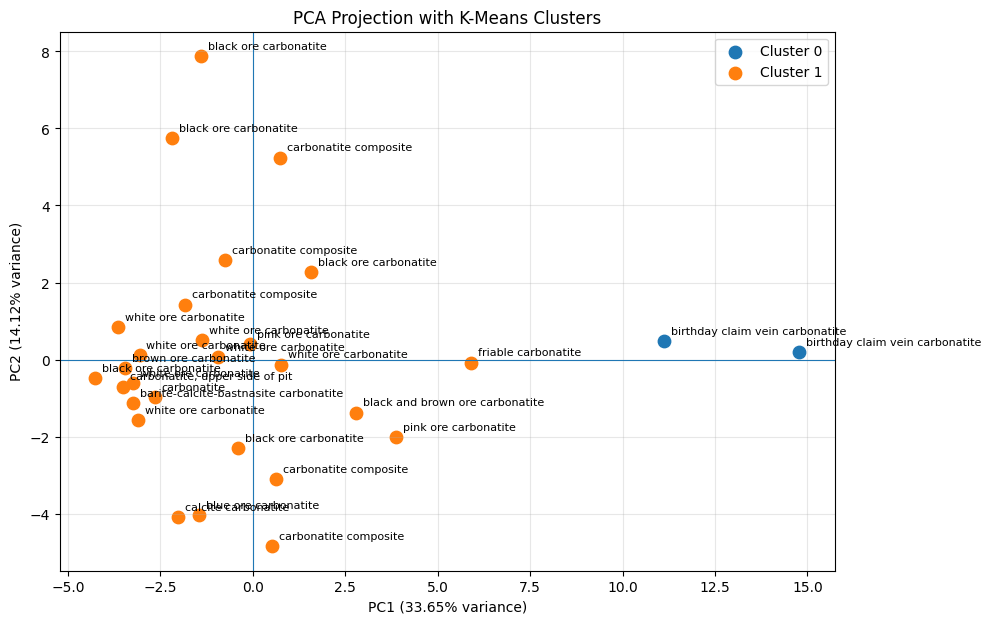

In [ ]:
# Step 126: Final PCA + K-Means visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df['Cluster'].unique()):
    subset = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        s=80,
        label=f'Cluster {cluster}'
    )

    for _, row in subset.iterrows():
        plt.annotate(
            row['Description'],
            (row['PC1'], row['PC2']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(
    f"PC1 ({pca_11.explained_variance_ratio_[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca_11.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title("PCA Projection with K-Means Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

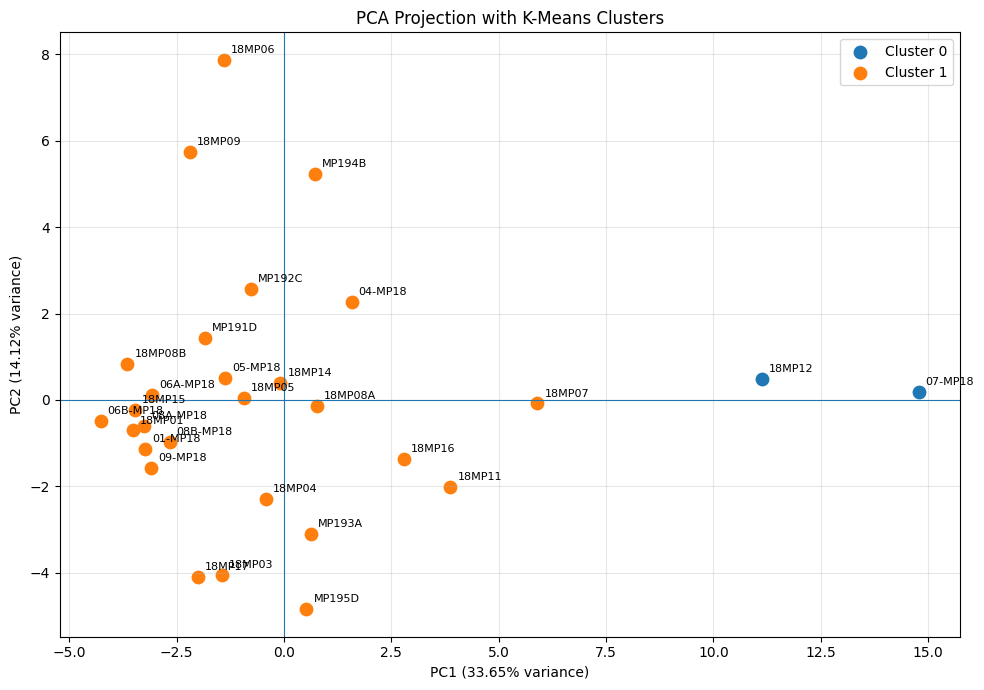

In [ ]:
# Step 126B: Clean PCA + K-Means visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df['Cluster'].unique()):
    subset = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        s=80,
        label=f'Cluster {cluster}'
    )

    for idx, row in subset.iterrows():
        plt.annotate(
            row['Field_ID'] if 'Field_ID' in pca_df.columns else df_clean.loc[idx, 'Field_ID'],
            (row['PC1'], row['PC2']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(
    f"PC1 ({pca_11.explained_variance_ratio_[0]*100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca_11.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title("PCA Projection with K-Means Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

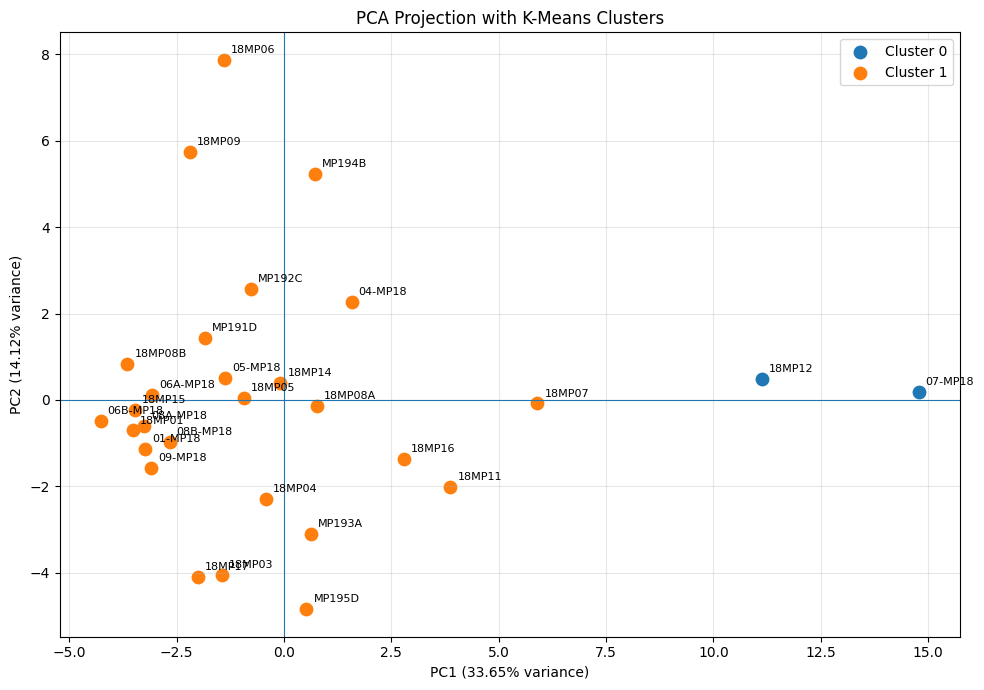

In [ ]:
# Step 126B: Clean PCA + K-Means visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df['Cluster'].unique()):
    subset = pca_df[pca_df['Cluster'] == cluster]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        s=80,
        label=f'Cluster {cluster}'
    )

    for idx, row in subset.iterrows():
        plt.annotate(
            row['Field_ID'] if 'Field_ID' in pca_df.columns else df_clean.loc[idx, 'Field_ID'],
            (row['PC1'], row['PC2']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=8
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(
    f"PC1 ({pca_11.explained_variance_ratio_[0]*100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca_11.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title("PCA Projection with K-Means Clusters")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Step 127: Final sample-level results table

final_sample_results = pd.DataFrame({
    'Lab_number': df_clean['Lab_number'],
    'Field_ID': df_clean['Field_ID'],
    'Description': df_clean['Description'],
    'Sample_source': df_clean['Sample_source'],
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Cluster': cluster_labels
})

final_sample_results = final_sample_results.sort_values(
    ['Cluster', 'PC1']
).reset_index(drop=True)

print(final_sample_results.to_string(index=False))

Lab_number Field_ID                           Description Sample_source       PC1       PC2  Cluster
  C-470517   18MP12       birthday claim vein carbonatite       outcrop 11.123777  0.479384        0
  C-466346  07-MP18       birthday claim vein carbonatite       outcrop 14.782367  0.192601        0
  C-466345 06B-MP18                 black ore carbonatite       outcrop -4.273236 -0.481818        1
  C-470514  18MP08B                 white ore carbonatite       outcrop -3.645860  0.833208        1
  C-470507   18MP01        carbonatite, upper side of pit       outcrop -3.523451 -0.707346        1
  C-470519   18MP15                 brown ore carbonatite       outcrop -3.467681 -0.227091        1
  C-466347 08A-MP18                 white ore carbonatite       outcrop -3.253861 -0.611990        1
  C-466341  01-MP18 barite-calcite-bastnasite carbonatite       outcrop -3.237846 -1.132255        1
  C-466349  09-MP18                 white ore carbonatite       outcrop -3.099682 -1.576362

In [ ]:
# Step 128: Save final sample-level results

final_sample_results.to_csv(
    'final_carbonatite_PCA_KMeans_results.csv',
    index=False
)

print("Final results saved successfully.")
print("File: final_carbonatite_PCA_KMeans_results.csv")
print("Rows:", len(final_sample_results))
print("Columns:", len(final_sample_results.columns))

Final results saved successfully.
File: final_carbonatite_PCA_KMeans_results.csv
Rows: 29
Columns: 7


## 6. CNN Classification (all results in percent %)

A 1D-CNN is trained on the standardized chemical features (`X_scaled`) to predict the K-Means cluster (`cluster_labels`). Variance and accuracy are both reported as **percentages**.

**Note:** with only 29 samples (cluster 0 has just 2), a single train/test split is unreliable, so repeated stratified cross-validation is used. Results are indicative, not definitive.

In [ ]:
# Step 129: Variance and accuracy in percentage (%)
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import balanced_accuracy_score

np.random.seed(42); tf.random.set_seed(42)

# Make sure labels are the final K=2 clusters (same as Step 72), even if Step 71 was re-run
cluster_labels = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_pca_11)

# PCA explained variance as percentage
pca_table = pd.DataFrame({
    'Explained_Variance_%': (pca_11.explained_variance_ratio_ * 100).round(2),
    'Cumulative_%': (np.cumsum(pca_11.explained_variance_ratio_) * 100).round(2)
}, index=[f'PC{i}' for i in range(1, 12)])
print(pca_table)

# CNN input: (samples, features, 1)
X_cnn = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1).astype('float32')
y_cnn = np.asarray(cluster_labels)

print("\nCNN input shape:", X_cnn.shape)
print("Class distribution (%):")
print((pd.Series(y_cnn).value_counts(normalize=True) * 100).round(2))

In [ ]:
# Step 130: CNN model + repeated stratified cross-validation

def build_cnn(n_features, n_classes):
    model = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(16, 3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

n_classes = len(np.unique(y_cnn))
cv = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=42)

cnn_acc, cnn_bal, rf_acc = [], [], []
y_true_all, y_pred_all = [], []

for train_idx, test_idx in cv.split(X_cnn, y_cnn):
    # class weights so the small cluster is not ignored
    counts = np.bincount(y_cnn[train_idx], minlength=n_classes)
    cw = {c: len(train_idx) / (n_classes * max(counts[c], 1)) for c in range(n_classes)}

    model = build_cnn(X_cnn.shape[1], n_classes)
    model.fit(X_cnn[train_idx], y_cnn[train_idx],
              epochs=100, batch_size=8, class_weight=cw, verbose=0)

    pred = model.predict(X_cnn[test_idx], verbose=0).argmax(axis=1)
    cnn_acc.append(accuracy_score(y_cnn[test_idx], pred) * 100)
    cnn_bal.append(balanced_accuracy_score(y_cnn[test_idx], pred) * 100)
    y_true_all.extend(y_cnn[test_idx]); y_pred_all.extend(pred)

    # Random Forest baseline on same split
    rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
    rf.fit(X_scaled[train_idx], y_cnn[train_idx])
    rf_acc.append(accuracy_score(y_cnn[test_idx], rf.predict(X_scaled[test_idx])) * 100)

print(f"CNN Accuracy          : {np.mean(cnn_acc):.2f}% (+/- {np.std(cnn_acc):.2f}%)")
print(f"CNN Balanced Accuracy : {np.mean(cnn_bal):.2f}% (+/- {np.std(cnn_bal):.2f}%)")
print(f"Random Forest Accuracy: {np.mean(rf_acc):.2f}% (+/- {np.std(rf_acc):.2f}%)")

In [ ]:
# Step 131: Confusion matrix (percent) and classification report

cm = confusion_matrix(y_true_all, y_pred_all)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=[f'Cluster {i}' for i in range(n_classes)],
            yticklabels=[f'Cluster {i}' for i in range(n_classes)])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('CNN Confusion Matrix (% of each actual cluster)')
plt.show()

print(classification_report(y_true_all, y_pred_all, zero_division=0))

In [ ]:
# Step 132: Final CNN on all data, accuracy curve in percent

final_cnn = build_cnn(X_cnn.shape[1], n_classes)
counts = np.bincount(y_cnn, minlength=n_classes)
cw = {c: len(y_cnn) / (n_classes * counts[c]) for c in range(n_classes)}
hist = final_cnn.fit(X_cnn, y_cnn, epochs=100, batch_size=8,
                     class_weight=cw, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(np.array(hist.history['accuracy']) * 100)
plt.xlabel('Epoch'); plt.ylabel('Training Accuracy (%)')
plt.title('CNN Training Accuracy (%)'); plt.grid(alpha=0.3)
plt.show()

print(f"Final CNN training accuracy: {hist.history['accuracy'][-1] * 100:.2f}%")
print(f"Cross-validated CNN accuracy: {np.mean(cnn_acc):.2f}%")

**CNN interpretation:** the cross-validated accuracy (in %) is the reliable figure; training accuracy is optimistic. Because the target is the K-Means label (2 vs 27 samples) and the data are very small, this CNN confirms that the clusters are learnable from the chemistry. It should not be read as a general geological classifier.

## Limitations

1. **Small sample size:** The dataset contains only 29 samples, so PCA and K-Means results should be considered exploratory rather than broadly generalizable.

2. **Missing data:** Several chemical variables contain missing values. WDXRF measurements are particularly incomplete, with 17 of the 29 samples having at least one missing WDXRF variable and 9 samples having all WDXRF variables missing.

3. **Special negative values:** The dataset contains negative numerical codes such as -9999, -0.01, -0.5, -1, -5, and -10. Their exact laboratory meaning is not documented in the supplied CSV. In this analysis, negative chemical values were treated as missing values, while valid negative geographic longitude values were retained. This preprocessing assumption should be verified against the original laboratory/data documentation.

4. **Imputation:** Missing chemical values were median-imputed before PCA and clustering. Because missingness is structured across samples and analytical methods, imputed values may influence some secondary PCA dimensions.

5. **Feature redundancy:** Several elemental measurements and their corresponding oxide measurements are highly correlated. A sensitivity analysis removing redundant oxide variables showed that the dominant PC1 structure remained highly similar.

6. **Influence of extreme samples:** The two Birthday Claim vein carbonatite samples have extreme positive PC1 scores and substantially influence the PCA structure and K-Means solution. They were retained because there is no evidence in the supplied dataset that they are erroneous measurements.

7. **Clustering stability:** K-Means identified two groups in the baseline analysis, but cluster membership and silhouette strength changed under alternative preprocessing choices. Therefore, the clusters should not be interpreted as definitive geological classifications.

8. **Categorical descriptions:** The Description field contains many small or singleton categories. Therefore, it was used as descriptive metadata rather than as a conventional supervised ML target.

## Final Conclusion

This study applied an unsupervised machine learning workflow to characterize chemical variation among 29 carbonatite samples. After data cleaning, handling missing values, feature selection, median imputation, and standardization, Principal Component Analysis (PCA) was used to reduce the dimensionality of the chemical dataset.

The PCA showed that 11 principal components explained 91.20% of the standardized variance. PC1 alone explained 33.65% of the variance and was primarily associated with an REE/Y enrichment gradient, contrasted with relatively higher Ca, Mg, Mn, and K-related variables. This interpretation was supported by an independent ICP-AES-MS-only PCA, whose PC1 scores showed a correlation of 0.9971 with the original PC1.

K-Means clustering was evaluated for multiple values of K, with K=2 producing the highest silhouette score in the baseline analysis. The resulting two-cluster solution separated the two Birthday Claim vein carbonatite samples from the remaining 27 samples. These two samples also occupied the extreme positive end of PC1 and showed substantially higher standardized REE/Y concentrations.

However, sensitivity analysis showed that the clustering was affected by preprocessing choices and by the two extreme Birthday Claim samples. Therefore, the K-Means groups should be interpreted as an exploratory pattern rather than as definitive geological classifications.

Overall, the analysis demonstrates that unsupervised machine learning can identify and summarize major patterns of chemical variability within this carbonatite dataset. The most consistent finding is the strong REE/Y-associated chemical gradient represented by PC1, while the clustering results provide an exploratory indication of chemically distinctive samples that can be investigated further using additional geological information and a larger, better-documented dataset.